# Hierarchical inference of a phenomenological model

In this notebook, we show how we can use the 2-state reduced model to accelerate the parameter inference of a phenomenological model (the `TxTlExtract`-based model, see Model construction.ipynb)

Note that the `DATA_FILE` is the experimental data downloaded from [zjuradoq/PURE_CRN_models](https://github.com/zjuradoq/PURE_CRN_models). Once you have the data, you can run through the whole notebook.

The high-level inference of the 2-state model, behavioral GP learning, baseline inference, and guided inference workflows are shown in this notebook.

Also note that the actual inference runs should be done on an HPC or on a computer server that can run code for long times uninterrupted. We ran the inference code on Pinnacles cluster at UC Merced. 

Plotting and data saving settings

In [11]:
from pathlib import Path
import hashlib
import importlib.metadata
import json
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import corner
from scipy.stats import wasserstein_distance
from scipy.special import ndtr
from scipy.stats import qmc
from emcee.moves import StretchMove
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, RBF
from bioscrape.types import Model
from bioscrape.simulator import py_simulate_model
from IPython.display import display

REPO_ROOT = next(parent for parent in (Path.cwd(), *Path.cwd().parents)
                 if (parent / "hierarch_inf").is_dir())
import sys
sys.path.insert(0, str(REPO_ROOT))

APPLICATION = REPO_ROOT / "examples"
EXAMPLES = REPO_ROOT / "examples"
MODEL_DIR = APPLICATION / "models"
GP_RESULTS = APPLICATION / "results"

RUN_TAG = "1020"
RESULTS_DIR = EXAMPLES / "results"
BASELINE_FILE = RESULTS_DIR / f"p_base_{RUN_TAG}.npz"
GUIDED_FILES = {
    "GP-guided 0.8": RESULTS_DIR / f"p_gp_z0.8_{RUN_TAG}.npz",
}
REDUCED_FILE = RESULTS_DIR / "reduced_model_inference_10k_1020.npz"
MODEL_FILE = MODEL_DIR / "gfp_expression_bioscrape.xml"
REDUCED_MODEL_FILE = MODEL_DIR / "gfp_reduced_TX.xml"
DATA_FILE = REPO_ROOT/ "examples/data/degfp61_data_tidy.csv"
GP_FILE = GP_RESULTS / "gp_hp_1020.npz"
GP_RANDOM_FILE = GP_RESULTS / "gp_hp_rand_1020.npz"
GP_INPUT_FILE = GP_RESULTS / "gp_hierarchid_inputs_1020.npz"
TRAINING_HISTORY_FILE = GP_RESULTS / "gp_hp_history_1020.npz"
TIMING_FILE = GP_RESULTS / "gp_hp_timing_1020.json"
OUT = EXAMPLES / "figures/Phenomenological"
OUT.mkdir(parents=True, exist_ok=True)
figure_settings = {}

COLORS = {"Baseline": "#0072B2", "GP-guided 0.5": "#CC79A7",
          "GP-guided 0.8": "#D55E00", "Reduced": "#009E73", "Phenomenological": "#666666"}
LINESTYLES = {"Baseline": "-", "GP-guided 0.5": "-.", "GP-guided 0.8": "--"}
DISPLAY_LABELS = {"Baseline": "Baseline", "GP-guided 0.5": r"GP, $\zeta=0.5$",
                  "GP-guided 0.8": r"GP, $\zeta=0.8$", "Reduced": "High-level", "Phenomenological": "Phenomenological"}
PARAMETER_LABELS = {
    "kb_tx": r"$k_{b,tx}$", "ku_tx": r"$k_{u,tx}$",
    "kb_tl": r"$k_{b,tl}$", "ku_tl": r"$k_{u,tl}$",
    "ktx": r"$k_{tx}$", "ktl": r"$k_{tl}$", "kdil": r"$k_{dil}$",
    "K_0": r"$K_0$", "K_1": r"$K_1$", "K_2": r"$K_2$", "kdeg": r"$k_{deg}$",
}
plt.rcParams.update({
    "font.family": "serif", "font.serif": ["DejaVu Serif"],
    "mathtext.fontset": "dejavuserif", "font.size": 8,
    "axes.labelsize": 8, "axes.titlesize": 8, "legend.fontsize": 7,
    "axes.titlelocation": "left", "axes.titleweight": "normal",
    "xtick.labelsize": 7, "ytick.labelsize": 7,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.linewidth": 0.6, "lines.linewidth": 1.4,
    "pdf.fonttype": 42, "ps.fonttype": 42,
    "savefig.dpi": 300, "figure.dpi": 130,
})


def save_figure(fig, name):
    """Export a figure as PDF and PNG, then display and close it."""
    for extension in ("pdf", "png"):
        fig.savefig(OUT / f"{name}.{extension}", bbox_inches="tight", pad_inches=0.03)
    plt.show()
    plt.close(fig)


def sha256(path):
    """Return the SHA256 digest of an input file for the source record."""
    with path.open("rb") as handle:
        return hashlib.file_digest(handle, "sha256").hexdigest()


## Reconstruct GP_hp and the saved learning history

Load the nine-state checkpoint, its independent test points and the kernel
histories for GP-MPM and the random comparison. Both methods share 129
initial observations and each adds 200 evaluations in the same neighborhood.


In [12]:
with np.load(GP_FILE, allow_pickle=False) as record:
    gp_archive = {key: record[key] for key in record.files}
with np.load(GP_RANDOM_FILE, allow_pickle=False) as record:
    gp_random_archive = {key: record[key] for key in record.files}
with np.load(TRAINING_HISTORY_FILE, allow_pickle=False) as record:
    training_history = {key: record[key] for key in record.files}
gp_timing = json.loads(TIMING_FILE.read_text(encoding="utf-8"))
gp_names = gp_archive["detailed_param_names"].tolist()
gp_lower, gp_upper = gp_archive["lower_bounds_detailed"], gp_archive["upper_bounds_detailed"]
epsilon, gamma = float(gp_archive["epsilon"]), float(gp_archive["gamma"])
validity_scale = float(gp_archive["validity_scale"])
assert epsilon == .5 and gamma == .5
np.testing.assert_allclose(gp_random_archive["validity_scale"], validity_scale)
np.testing.assert_array_equal(training_history["X_gp"], gp_archive["X_gp"])
np.testing.assert_array_equal(training_history["rho_gp"], gp_archive["rho_gp"])
np.testing.assert_array_equal(training_history["X_test"], gp_archive["X_test"])
np.testing.assert_array_equal(training_history["X_random"], gp_random_archive["X_gp"])
np.testing.assert_array_equal(training_history["rho_random"], gp_random_archive["rho_gp"])
np.testing.assert_allclose(gp_random_archive["gp_noise"], gp_archive["gp_noise"])


def recorded_gp(constant, length_scales, X, discrepancy):
    """Reconstruct a GP using its saved training observations and kernel."""
    gp = GaussianProcessRegressor(
        kernel=ConstantKernel(float(constant), "fixed") * RBF(length_scales, "fixed"),
        alpha=float(gp_archive["gp_noise"]), optimizer=None, normalize_y=False)
    gp.fit(X, (epsilon-discrepancy)/validity_scale)
    return gp


trained_gp = recorded_gp(gp_archive["gp_kernel_constant"], gp_archive["gp_kernel_length_scale"],
                         gp_archive["X_gp"], gp_archive["rho_gp"])
np.testing.assert_allclose(gp_archive["v_gp"], epsilon-gp_archive["rho_gp"])
np.testing.assert_array_equal(gp_archive["true_test_valid"], training_history["rho_test"] <= epsilon)
print("GP initial points:", int(gp_archive["T0"]), "; acquisitions:", int(gp_archive["N_MPM_STEPS"]))
np.testing.assert_allclose(training_history["mpm_kernel_constants"][-1], gp_archive["gp_kernel_constant"])
np.testing.assert_allclose(training_history["mpm_kernel_length_scales"][-1], gp_archive["gp_kernel_length_scale"])
np.testing.assert_allclose(training_history["random_kernel_constants"][-1], gp_random_archive["gp_kernel_constant"])
np.testing.assert_allclose(training_history["random_kernel_length_scales"][-1], gp_random_archive["gp_kernel_length_scale"])

assert gp_archive["mapping"].item() == "GP_hp"
assert int(gp_archive["n_states"]) == 9
assert gp_archive["test_points_held_out_from_this_gp"].item()
assert gp_random_archive["test_points_held_out_from_this_gp"].item()


GP initial points: 129 ; acquisitions: 200


## Learning the Gaussian Process: Independent test set and full learning curves

Reconstruct both learning curves through 200 acquisitions using the saved
kernels and evaluation prefixes. The common 200-point Sobol test set was
evaluated independently of both complete training sets. Balanced error
averages the compatible and incompatible misclassification rates.


In [13]:
N_TEST_POINTS = 200
TEST_DESIGN_SEED = 2026
TEST_FILE = GP_RESULTS / "gp_hp_test_1020.npz"
LEARNING_CURVE_STRIDE = 10
INITIAL_POINTS = int(gp_archive["T0"])
ACQUISITION_BUDGET = int(gp_archive["N_MPM_STEPS"])
with np.load(TEST_FILE, allow_pickle=False) as record:
    test_X, test_rho = record["X_test"], record["rho"]
    test_b = record["b"]
    assert int(record["test_design_seed"]) == TEST_DESIGN_SEED
    assert record["detailed_model_SHA256"].item() == sha256(MODEL_FILE)
np.testing.assert_array_equal(test_X, training_history["X_test"])
np.testing.assert_allclose(test_rho, training_history["rho_test"])
assert len(test_X) == N_TEST_POINTS
for training_X in (gp_archive["X_gp"], gp_random_archive["X_gp"]):
    assert not np.any(np.all(np.isclose(test_X[:, None], training_X[None],
                                       rtol=0, atol=1e-12), axis=2))
test_truth = test_rho <= epsilon
np.testing.assert_array_equal(test_truth, gp_archive["true_test_valid"])
test_mean, test_sd = trained_gp.predict(test_X, return_std=True)
test_probability = ndtr(test_mean/np.maximum(test_sd, 1e-12))
print("Independent test tuples:", len(test_X), "; compatible:", int(test_truth.sum()),
      "; incompatible:", int((~test_truth).sum()))
budgets = np.arange(0, ACQUISITION_BUDGET+1, LEARNING_CURVE_STRIDE)
training_rows = []
assert test_truth.any() and (~test_truth).any()
for method, prefix, X_key, rho_key in (
    ("GP-MPM", "mpm", "X_gp", "rho_gp"),
    ("Uniform random", "random", "X_random", "rho_random")):
    for budget in budgets:
        end = INITIAL_POINTS+int(budget)
        gp = recorded_gp(training_history[prefix+"_kernel_constants"][budget],
                         training_history[prefix+"_kernel_length_scales"][budget],
                         training_history[X_key][:end], training_history[rho_key][:end])
        predicted = gp.predict(test_X) >= 0
        compatible_kept = float(predicted[test_truth].mean())
        incompatible_rejected = float((~predicted[~test_truth]).mean())
        training_rows.append(dict(method=method, additional_evaluations=int(budget),
            test_error=float(np.mean(predicted != test_truth)),
            balanced_error=.5*(2-compatible_kept-incompatible_rejected),
            compatible_kept=compatible_kept, incompatible_rejected=incompatible_rejected))
training_comparison = pd.DataFrame(training_rows)
training_comparison.to_csv(OUT / "gp_training_comparison.csv", index=False)
local_validation = pd.DataFrame([dict(zeta=cutoff,
    compatible_kept=int(np.sum((test_probability > cutoff) & test_truth)),
    compatible_total=int(test_truth.sum()),
    incompatible_rejected=int(np.sum((test_probability <= cutoff) & ~test_truth)),
    incompatible_total=int((~test_truth).sum())) for cutoff in (.5, .8)])
local_validation.to_csv(OUT / "gp_local_validation.csv", index=False)
display(training_comparison.groupby("method").tail(1))
display(local_validation)


Independent test tuples: 200 ; compatible: 44 ; incompatible: 156


,method,additional_evaluations,test_error,balanced_error,compatible_kept,incompatible_rejected
20,GP-MPM,200,0.09,0.082168,0.931818,0.903846
41,Uniform random,200,0.09,0.122960,0.818182,0.935897


,zeta,compatible_kept,compatible_total,incompatible_rejected,incompatible_total
0,0.5,41,44,141,156
1,0.8,21,44,155,156


## GP filtering of MCMC proposals

For illutsration purposes only, we generate some parameter proposals from 16 snapshots spanning the last 10,000 ensemble steps of each phenomenological run. Then, we select 500 parameter proposals from each run before calculating the GP scores. Then, we apply both
filtering levels to the same pooled 1000 proposals. Histograms show
percentages of this original pool, and orange outlines show retained proposals.

,zeta,proposed,retained,rejected,retained_percent
0,0.5,1000,509,491,50.9
1,0.8,1000,354,646,35.4


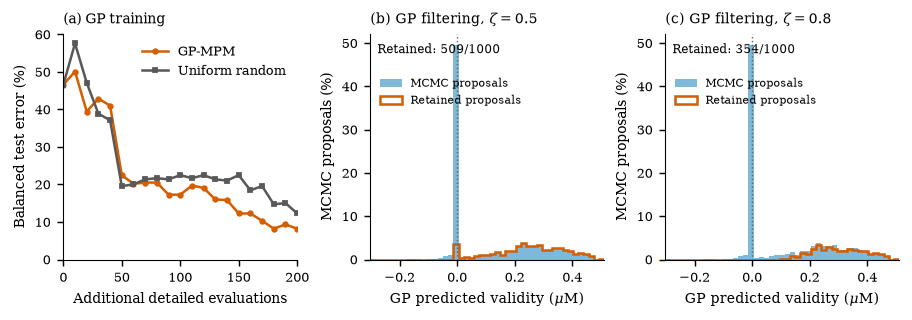

In [14]:
SCREENING_ENSEMBLE_FILES = {"Baseline": BASELINE_FILE, **GUIDED_FILES}
N_PROPOSALS_PER_RUN = 500
N_SCREENING_PROPOSALS = N_PROPOSALS_PER_RUN*len(SCREENING_ENSEMBLE_FILES)
SCREENING_PROPOSAL_SEED = 2026
SCREENING_WINDOW_STEPS = 10000
N_ENSEMBLE_SNAPSHOTS = 16
STRETCH_SCALE = 2.0
SCREENING_LEVELS = (.5, .8)
VALIDITY_BINS = 45

rng = np.random.RandomState(SCREENING_PROPOSAL_SEED)
stretch_move = StretchMove(a=STRETCH_SCALE)
selected_parameters, selected_steps, selected_walkers, selected_methods = [], [], [], []
proposal_design = {}
for method, source_file in SCREENING_ENSEMBLE_FILES.items():
    with np.load(source_file, allow_pickle=False) as record:
        screening_chain = record["chain"]
        screening_prior = json.loads(record["prior_json"].item())
        np.testing.assert_array_equal(record["param_names"], gp_names)
        assert record["model_SHA256"].item() == gp_archive["detailed_model_SHA256"].item()
        assert len(screening_chain)-SCREENING_WINDOW_STEPS >= int(record["burn"])
    np.testing.assert_array_equal([screening_prior[p][1] for p in gp_names], gp_lower)
    np.testing.assert_array_equal([screening_prior[p][2] for p in gp_names], gp_upper)
    snapshot_steps = np.linspace(len(screening_chain)-SCREENING_WINDOW_STEPS,
                                 len(screening_chain)-1,N_ENSEMBLE_SNAPSHOTS,dtype=int)
    raw_parameters, source_steps, source_walkers = [], [], []
    for step in snapshot_steps:
        ensemble = screening_chain[step]
        halves = np.array_split(rng.permutation(len(ensemble)),2)
        for active,complement in (halves,halves[::-1]):
            proposal,_ = stretch_move.get_proposal(ensemble[active],[ensemble[complement]],rng)
            raw_parameters.append(proposal)
            source_steps.extend([int(step)]*len(active))
            source_walkers.extend(active)
    raw_parameters = np.concatenate(raw_parameters)
    prior_valid = np.all((raw_parameters>gp_lower)&(raw_parameters<gp_upper),axis=1)
    selection = rng.choice(np.flatnonzero(prior_valid),size=N_PROPOSALS_PER_RUN,replace=False)
    selected_parameters.append(raw_parameters[selection])
    selected_steps.append(np.asarray(source_steps)[selection])
    selected_walkers.append(np.asarray(source_walkers)[selection])
    selected_methods.extend([method]*N_PROPOSALS_PER_RUN)
    proposal_design[method] = dict(source_file=str(source_file),source_SHA256=sha256(source_file),
        snapshot_steps=snapshot_steps.tolist(),raw_proposals=len(raw_parameters),
        ordinary_prior_valid=int(prior_valid.sum()),selected=N_PROPOSALS_PER_RUN)
proposal_parameters = np.concatenate(selected_parameters)
proposal_steps = np.concatenate(selected_steps)
proposal_walkers = np.concatenate(selected_walkers)
proposal_methods = np.array(selected_methods)
proposal_X = np.log(proposal_parameters/gp_lower)/np.log(gp_upper/gp_lower)
proposal_mean, proposal_sd = trained_gp.predict(proposal_X, return_std=True)
proposal_probability = ndtr(proposal_mean/np.maximum(proposal_sd, 1e-12))
proposal_validity_uM = proposal_mean*validity_scale
proposal_screening = pd.DataFrame([dict(zeta=cutoff, proposed=N_SCREENING_PROPOSALS,
    retained=int(np.sum(proposal_probability > cutoff)),
    rejected=int(np.sum(proposal_probability <= cutoff)),
    retained_percent=100*float(np.mean(proposal_probability > cutoff)))
    for cutoff in SCREENING_LEVELS])
display(proposal_screening)
proposal_screening.to_csv(OUT / "gp_mcmc_proposal_screening.csv", index=False)
np.savez_compressed(OUT/"gp_mcmc_proposal_screening.npz",parameters=proposal_parameters,
    param_names=np.array(gp_names),normalized_log_parameters=proposal_X,
    gp_mean_uM=proposal_validity_uM,gp_sd_uM=proposal_sd*validity_scale,
    gp_probability=proposal_probability,screening_levels=np.array(SCREENING_LEVELS),
    proposal_seed=SCREENING_PROPOSAL_SEED,proposal_source_method=proposal_methods,
    proposal_source_step=proposal_steps,proposal_source_walker=proposal_walkers,
    proposal_design_json=np.array(json.dumps(proposal_design)),stretch_scale=STRETCH_SCALE,
    GP_SHA256=np.array(sha256(GP_FILE)))
fig, axes = plt.subplots(1, 3, figsize=(6.9, 2.35), layout="constrained")
for method, color, marker in (("GP-MPM", COLORS["GP-guided 0.8"], "o"),
                               ("Uniform random", ".35", "s")):
    block = training_comparison[training_comparison["method"] == method]
    axes[0].plot(block["additional_evaluations"], 100*block["balanced_error"],
                 marker=marker, markersize=2.5, color=color, label=method)
axes[0].set(title="(a) GP training", xlabel="Additional detailed evaluations",
            ylabel="Balanced test error (%)", xlim=(0, ACQUISITION_BUDGET), ylim=(0, None))
axes[0].legend(frameon=False)
bins = np.linspace(proposal_validity_uM.min(), proposal_validity_uM.max(), VALIDITY_BINS+1)
for panel, cutoff in enumerate(SCREENING_LEVELS, 1):
    retained = proposal_probability > cutoff
    ax = axes[panel]
    ax.hist(proposal_validity_uM, bins=bins,
            weights=np.full(N_SCREENING_PROPOSALS, 100/N_SCREENING_PROPOSALS),
            color=COLORS["Baseline"], alpha=.5, label="MCMC proposals")
    ax.hist(proposal_validity_uM[retained], bins=bins,
            weights=np.full(retained.sum(), 100/N_SCREENING_PROPOSALS),
            histtype="step", linewidth=1.4, color=COLORS["GP-guided 0.8"], label="Retained proposals")
    ax.axvline(0, color=".4", linestyle=":", linewidth=.8)
    ax.set(title=fr"({chr(97+panel)}) GP filtering, $\zeta={cutoff:g}$",
           xlabel=r"GP predicted validity ($\mu$M)", ylabel="MCMC proposals (%)",
           xlim=(bins[0], bins[-1]))
    ax.text(.03, .96, f"Retained: {retained.sum()}/{N_SCREENING_PROPOSALS}",
            transform=ax.transAxes, ha="left", va="top", fontsize=6.5)
    ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0, .85), fontsize=6)
axes[1].sharey(axes[2])
save_figure(fig, "gp_training_and_screening")
figure_settings["gp_training_and_screening"] = dict(
    learning_curve_stride=LEARNING_CURVE_STRIDE,held_out_test_points=len(test_truth),
    independent_test_seed=TEST_DESIGN_SEED,independent_test_SHA256=sha256(TEST_FILE),
    proposal_count=N_SCREENING_PROPOSALS,proposal_seed=SCREENING_PROPOSAL_SEED,
    proposal_design="500 ordinary-prior-valid stretch proposals from each run, selected before GP scoring",
    source_ensembles=proposal_design,window_steps=SCREENING_WINDOW_STEPS,
    ensemble_snapshots=N_ENSEMBLE_SNAPSHOTS,stretch_scale=STRETCH_SCALE,
    screening_levels=list(SCREENING_LEVELS),validity_bins=VALIDITY_BINS)
del screening_chain,ensemble


## Load the completed phenomenological and high-level chains

We provide the data from inference runs on the Pinnacles cluster at UC Merced so that figures from the paper can be regenerated.

In [15]:
archive_paths = {"Baseline": BASELINE_FILE, **GUIDED_FILES}
guided_names = tuple(GUIDED_FILES)
archives = {}
for name, path in archive_paths.items():
    with np.load(path, allow_pickle=False) as record:
        archives[name] = {key: record[key] for key in record.files}
with np.load(REDUCED_FILE, allow_pickle=False) as record:
    reduced_archive = {key: record[key] for key in record.files}
with np.load(GP_INPUT_FILE, allow_pickle=False) as record:
    gp_inputs = {key: record[key] for key in record.files}
param_names = archives["Baseline"]["param_names"].tolist()
labels = [PARAMETER_LABELS[name] for name in param_names]
ndim = len(param_names)
prior = json.loads(archives["Baseline"]["prior_json"].item())
lower = np.array([prior[name][1] for name in param_names])
upper = np.array([prior[name][2] for name in param_names])
fixed_detailed = json.loads(archives["Baseline"]["fixed_parameters_json"].item())
for name, archive in archives.items():
    assert archive["param_names"].tolist() == param_names
    assert json.loads(archive["prior_json"].item()) == prior
    assert json.loads(archive["fixed_parameters_json"].item()) == fixed_detailed
    assert archive["model_SHA256"].item() == sha256(MODEL_FILE)
    assert archive["data_SHA256"].item() == sha256(DATA_FILE)
    assert archive["concentration_unit"].item() == "uM"
    assert archive["time_unit"].item() == "min"
    assert archive["chain"].shape == (int(archive["nsteps"]), int(archive["nwalkers"]), ndim)
    assert archive["log_prob"].shape == archive["chain"].shape[:2]
    for key in ("nsteps", "nwalkers", "burn", "n_processes", "random_seed"):
        assert int(archive[key]) == int(archives["Baseline"][key])
    full_postburn_rows = (int(archive["nsteps"])-int(archive["burn"]))*int(archive["nwalkers"])
    np.testing.assert_allclose(archive["ess"], full_postburn_rows/archive["tau"], equal_nan=True)
screening_levels = {name: float(archives[name]["gp_screening_level"]) for name in guided_names}
assert list(screening_levels.values()) == [0.8]
for name in guided_names:
    assert archives[name]["gp_SHA256"].item() == sha256(GP_FILE)
assert archives["Baseline"]["initialization_mode"].item().startswith("Gaussian ball")
assert archives["GP-guided 0.8"]["joint_prior_evaluation"].item() == "batch"
assert not np.array_equal(archives["Baseline"]["initial_walkers"],
                          archives["GP-guided 0.8"]["initial_walkers"])
assert int(reduced_archive["nsteps"]) == 10000
assert int(reduced_archive["burn"]) == 5000
assert gp_archive["detailed_param_names"].tolist() == param_names
assert gp_archive["detailed_model_SHA256"].item() == sha256(MODEL_FILE)
np.testing.assert_allclose(gp_archive["lower_bounds_detailed"], lower)
np.testing.assert_allclose(gp_archive["upper_bounds_detailed"], upper)
OUT.mkdir(parents=True, exist_ok=True)

metadata = pd.DataFrame({name: {
    "steps": int(a["nsteps"]), "walkers": int(a["nwalkers"]),
    "burn_in_steps": int(a["burn"]), "processes": int(a["n_processes"]),
    "random_seed": int(a["random_seed"]),
    "full_postburn_rows": (int(a["nsteps"])-int(a["burn"]))*int(a["nwalkers"]),
    "detailed_inference_minutes": float(a["runtime_seconds"])/60,
    "mean_acceptance_fraction": float(a["acceptance_fraction"].mean()),
} for name, a in archives.items()})
display(metadata)
metadata.to_csv(OUT / "run_metadata.csv")
display(pd.DataFrame({"fixed_parameter": list(fixed_detailed), "value": list(fixed_detailed.values())}))
print("Phenomenological model states:", int(archives["Baseline"]["n_states"]))
print("Figures and summaries:", OUT)

print("Baseline initialization:", archives["Baseline"]["initialization_mode"].item())
print("Guided initialization:", archives["GP-guided 0.8"]["initialization_mode"].item())

assert all(int(a["n_states"]) == 9 for a in archives.values())
assert archives["GP-guided 0.8"]["gp_mapping"].item() == "GP_hp"


,Baseline,GP-guided 0.8
steps,4.000000e+04,4.000000e+04
walkers,2.560000e+02,2.560000e+02
burn_in_steps,5.000000e+03,5.000000e+03
processes,3.200000e+01,3.200000e+01
random_seed,2.026000e+03,2.026000e+03
full_postburn_rows,8.960000e+06,8.960000e+06
detailed_inference_minutes,9.238483e+01,8.497786e+01
mean_acceptance_fraction,6.572314e-02,2.472205e-01


,fixed_parameter,value
0,kb_deg,10.0
1,ku_deg,1.0
2,kdeg,0.1


Phenomenological model states: 9
Figures and summaries: c:\Users\ayush\Box\Research\hierarchical-validation-id\hierarch-inf\examples\figures\Phenomenological
Baseline initialization: Gaussian ball around nominal model rates, conditioned on prior bounds
Guided initialization: single GP-training centre with uniform log10 perturbations


## Posterior window and joint sampled MAP

Use the last 10,000 ensemble steps for posterior summaries and drawing
parameter tuples. Search all post-burn steps for the sampled MAP, retaining
its step and walker indices. All walkers and repeated states are included.

In [16]:
POSTERIOR_WINDOW_STEPS = 10000
REDUCED_POSTERIOR_WINDOW_STEPS = 5000
chains, samples, sample_start, map_parameters, map_locations = {}, {}, {}, {}, {}
for name, archive in archives.items():
    chain = archive["chain"]
    burn = int(archive["burn"])
    start = len(chain)-POSTERIOR_WINDOW_STEPS
    assert start >= burn, "Requested posterior window exceeds the available post-burn steps."
    chains[name] = chain
    sample_start[name] = start
    samples[name] = chain[start:].reshape(-1, ndim)
    flat_index = int(np.argmax(archive["log_prob"][burn:]))
    step, walker = np.unravel_index(flat_index, archive["log_prob"][burn:].shape)
    step += burn
    assert np.isfinite(archive["log_prob"][step, walker])
    map_parameters[name] = chain[step, walker].copy()
    map_locations[name] = dict(step=int(step), walker=int(walker),
                               log_posterior=float(archive["log_prob"][step, walker]))

reduced_names = reduced_archive["param_names"].tolist()
reduced_chain = reduced_archive["chain"]
reduced_start = len(reduced_chain)-REDUCED_POSTERIOR_WINDOW_STEPS
reduced_burn = int(reduced_archive["burn"])
assert reduced_start >= reduced_burn
reduced_samples = reduced_chain[reduced_start:].reshape(-1, len(reduced_names))
reduced_flat_index = int(np.argmax(reduced_archive["log_prob"][reduced_burn:]))
reduced_map_step, reduced_map_walker = np.unravel_index(
    reduced_flat_index, reduced_archive["log_prob"][reduced_burn:].shape)
reduced_map_step += reduced_burn
reduced_map = reduced_chain[reduced_map_step, reduced_map_walker].copy()
reduced_prior = json.loads(reduced_archive["prior_json"].item())
fixed_reduced = json.loads(reduced_archive["fixed_parameters_json"].item())

posterior_rows = []
summary_inputs = [(name, samples[name], param_names, map_parameters[name]) for name in archives]
summary_inputs.append(("Reduced", reduced_samples, reduced_names, reduced_map))
for name, values, names, theta in summary_inputs:
    quantiles = np.quantile(values, [.05, .5, .95], axis=0)
    for i, parameter in enumerate(names):
        posterior_rows.append(dict(method=name, parameter=parameter, sampled_MAP=float(theta[i]),
            q05=float(quantiles[0, i]), median=float(quantiles[1, i]), q95=float(quantiles[2, i])))
posterior_summary = pd.DataFrame(posterior_rows)
display(posterior_summary)
display(pd.DataFrame(map_locations).T)
posterior_summary.to_csv(OUT / "posterior_quantiles_and_MAP.csv", index=False)
pd.DataFrame(map_locations).T.to_csv(OUT / "sampled_MAP_locations.csv", index_label="method")


,method,parameter,sampled_MAP,q05,median,q95
0,Baseline,kb_tx,4992.486288,769.142183,8498.388189,75159.952347
1,Baseline,ku_tx,0.001204,0.002022,0.712399,391.356064
2,Baseline,kb_tl,0.051528,0.015081,0.750272,251.404514
3,Baseline,ku_tl,0.004251,0.002405,3.279317,614.966505
4,Baseline,ktx,264.805870,62.477551,709.352029,7938.490796
5,Baseline,ktl,0.174556,0.126941,0.191554,0.418268
6,Baseline,kdil,0.028478,0.019218,0.030747,0.066867
7,GP-guided 0.8,kb_tx,449.566078,377.065948,532.893309,699.799325
8,GP-guided 0.8,ku_tx,15.429624,33.785731,222.600186,810.932803
9,GP-guided 0.8,kb_tl,40.066625,40.734523,72.064273,149.433308


,step,walker,log_posterior
Baseline,26268.0,16.0,-21.274712
GP-guided 0.8,35199.0,15.0,-47.932271


## Parameter and log-posterior traces

Here we display walker chains. The vertical lines mark the burn-in and the
start of the posterior plotting window.

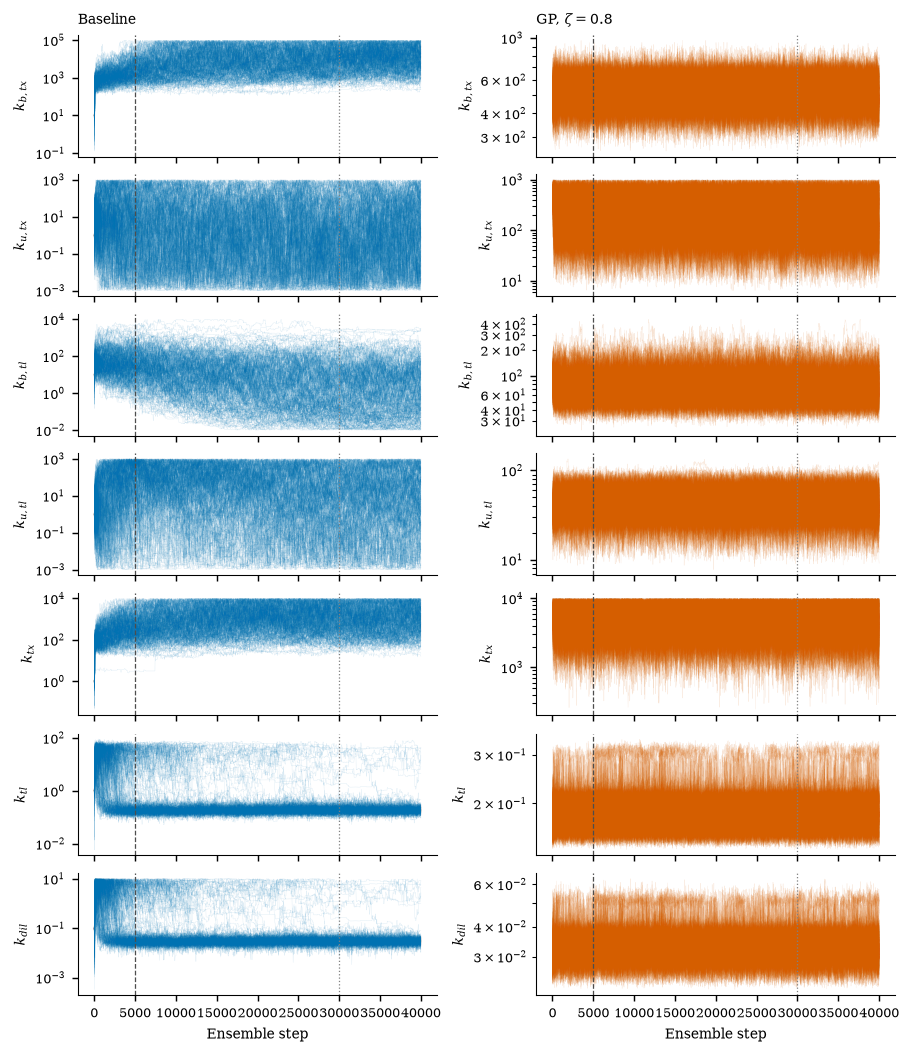

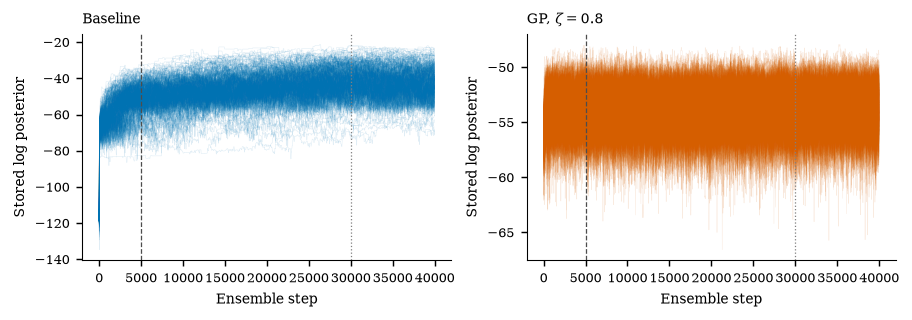

In [17]:
MAX_TRACE_STEPS = 1500
TRACE_ALPHA = 0.12
fig, axes = plt.subplots(ndim, len(archives), figsize=(6.9, 8.0), sharex="col", layout="constrained")
for column, (name, chain) in enumerate(chains.items()):
    stride = max(1, len(chain)//MAX_TRACE_STEPS)
    steps = np.unique(np.r_[np.arange(0, len(chain), stride), len(chain)-1])
    for j in range(ndim):
        ax = axes[j, column]
        ax.plot(steps, chain[steps, :, j], color=COLORS[name], alpha=TRACE_ALPHA,
                linewidth=.25, rasterized=True)
        ax.axvline(int(archives[name]["burn"]), color=".3", ls="--", lw=.7)
        ax.axvline(sample_start[name], color=".5", ls=":", lw=.7)
        ax.set(yscale="log", ylabel=labels[j])
        if j == 0:
            ax.set_title(DISPLAY_LABELS[name])
    axes[-1, column].set_xlabel("Ensemble step")
save_figure(fig, "parameter_traces")
figure_settings["parameter_traces"] = dict(max_trace_steps=MAX_TRACE_STEPS, alpha=TRACE_ALPHA)

fig, axes = plt.subplots(1, len(archives), figsize=(6.9, 2.35), layout="constrained")
for ax, (name, archive) in zip(axes, archives.items()):
    stride = max(1, int(archive["nsteps"])//MAX_TRACE_STEPS)
    steps = np.arange(0, int(archive["nsteps"]), stride)
    ax.plot(steps, archive["log_prob"][steps], color=COLORS[name], alpha=TRACE_ALPHA,
            linewidth=.3, rasterized=True)
    ax.axvline(int(archive["burn"]), color=".3", ls="--", lw=.7)
    ax.axvline(sample_start[name], color=".5", ls=":", lw=.7)
    ax.set(title=DISPLAY_LABELS[name], xlabel="Ensemble step", ylabel="Stored log posterior")
save_figure(fig, "log_posterior_traces")
figure_settings["log_posterior_traces"] = dict(max_trace_steps=MAX_TRACE_STEPS, alpha=TRACE_ALPHA)


## Experimental data

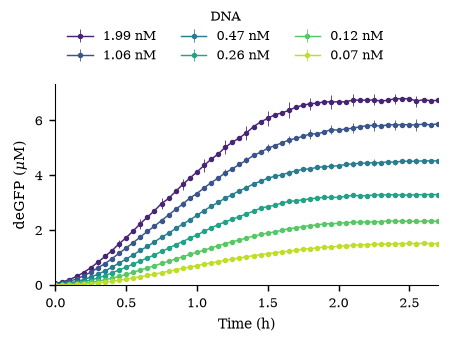

In [18]:
DNA_NM_TO_UM = float(archives["Baseline"]["DNA_NM_TO_UM"])
GFP_RFU_PER_UM = 5542.4
TRUNCATE_BEFORE_MIN = 15.0
TIME_MAX_MIN = 180.0
DATA_ERROR_EVERY = 3
df = pd.read_csv(DATA_FILE)
for column in ("na", "construct", "repeat"):
    df[column] = df[column].astype(str).str.strip()
for column in ("Time", "value", "na_conc"):
    df[column] = pd.to_numeric(df[column], errors="coerce")
df = df[(df["na"].str.lower() == "dna") & (df["construct"] == "MGapt-deGFP")].dropna(
    subset=["Time", "value", "na_conc", "repeat"])
df = df[df["Time"].between(TRUNCATE_BEFORE_MIN, TIME_MAX_MIN)].copy()
time_offset = float(archives["Baseline"]["time_offset_minutes"])
df["time_min"] = df["Time"]-time_offset
df["dna_uM"] = df["na_conc"]*DNA_NM_TO_UM
df["GFP_uM"] = df["value"]/GFP_RFU_PER_UM
dna_concs = archives["Baseline"]["dna_concs"]
dna_concs_nM = dna_concs/DNA_NM_TO_UM
timepoints = archives["Baseline"]["timepoints"]
replicates = sorted(df["repeat"].unique())
experimental = np.empty((len(dna_concs), len(replicates), len(timepoints)))
for c, dna in enumerate(dna_concs):
    for r, rep in enumerate(replicates):
        block = df[(df["dna_uM"] == dna) & (df["repeat"] == rep)].sort_values("time_min")
        np.testing.assert_allclose(block["time_min"], timepoints)
        experimental[c, r] = block["GFP_uM"]
data_mean, data_sd = experimental.mean(axis=1), experimental.std(axis=1, ddof=1)
for archive in (*archives.values(), reduced_archive, gp_archive, gp_inputs):
    np.testing.assert_allclose(archive["dna_concs"], dna_concs)
    np.testing.assert_allclose(archive["timepoints"], timepoints)
np.testing.assert_allclose(gp_inputs["experimental_mean_trajectories"], data_mean)
condition_colors = plt.get_cmap("viridis")(np.linspace(.1, .9, len(dna_concs)))
fig, ax = plt.subplots(figsize=(3.35, 2.55), layout="constrained")
for c, dna in enumerate(dna_concs_nM):
    ax.errorbar(timepoints/60, data_mean[c], yerr=data_sd[c], color=condition_colors[c],
                marker="o", markersize=2, linewidth=.8, elinewidth=.45,
                errorevery=DATA_ERROR_EVERY, label=f"{dna:g} nM")
ax.set(xlabel="Time (h)", ylabel=r"deGFP ($\mu$M)",
       xlim=(0, timepoints[-1]/60), ylim=(0, None))
handles, legend_labels = ax.get_legend_handles_labels()
fig.legend(handles, legend_labels, title="DNA", frameon=False, ncol=3,
           loc="outside upper center", title_fontsize=7)
save_figure(fig, "data")
figure_settings["data"] = dict(error_every=DATA_ERROR_EVERY)


## Joint sampled MAP fits

Simulate the BioCRNpyler nine-state model and the AutoReduce high-level
model with the fixed rates and resource pools.


In [19]:
assert reduced_archive["data_SHA256"].item() == sha256(DATA_FILE)
assert json.loads(gp_archive["fixed_reduced_parameters_json"].item()) == fixed_reduced
for name, archive in archives.items():
    model = Model(sbml_filename=str(MODEL_FILE))
    for species, value in json.loads(archive["enzyme_totals_json"].item()).items():
        np.testing.assert_allclose(model.get_species_dictionary()[species], value)
    assert set(param_names) | set(fixed_detailed) == set(model.get_parameter_dictionary())


def simulate_phenomenological(theta):
    """Simulate the nine-state GFP trajectories at the recorded DNA conditions."""
    model = Model(sbml_filename=str(MODEL_FILE))
    model.set_params({**fixed_detailed, **dict(zip(param_names, theta))})
    trajectories = []
    for dna in dna_concs:
        model.set_species({"DNA": float(dna)})
        trajectories.append(py_simulate_model(timepoints, Model=model)["GFP"].to_numpy(dtype=float))
    return np.asarray(trajectories)


def simulate_reduced(theta):
    """Simulate the high-level GFP trajectories at the recorded DNA conditions."""
    model = Model(sbml_filename=str(REDUCED_MODEL_FILE))
    model.set_params({**fixed_reduced, **json.loads(reduced_archive["enzyme_totals_json"].item()),
                      **dict(zip(reduced_names, theta))})
    trajectories = []
    for dna in dna_concs:
        model.set_params({"DNA": float(dna)})
        trajectories.append(py_simulate_model(timepoints, Model=model)["GFP"].to_numpy(dtype=float))
    return np.asarray(trajectories)


map_trajectories = {name: simulate_phenomenological(theta) for name, theta in map_parameters.items()}
reduced_map_trajectories = simulate_reduced(reduced_map)
map_trajectories["Reduced"] = reduced_map_trajectories
map_checks = [(name, map_parameters[name], prior, map_locations[name]["log_posterior"])
              for name in archives]
map_checks.append(("Reduced", reduced_map, reduced_prior,
                   float(reduced_archive["log_prob"][reduced_map_step, reduced_map_walker])))
model_parameter_names = {**{name: param_names for name in archives},
                         "Reduced": reduced_names}
for name, theta, model_prior, saved_logp in map_checks:
    names = model_parameter_names[name]
    lo = np.array([model_prior[p][1] for p in names])
    hi = np.array([model_prior[p][2] for p in names])
    residual_norm = float(np.linalg.norm(experimental-map_trajectories[name][:, None, :]))
    log_prior = float(-np.log(theta*np.log(hi/lo)).sum())
    np.testing.assert_allclose(saved_logp, -residual_norm+log_prior, atol=1e-4, rtol=0)
    print(name, "MAP residual norm:", residual_norm, "; saved log posterior:", saved_logp)
fit_table = pd.DataFrame({"DNA_nM": dna_concs_nM, "DNA_uM": dna_concs})
for name, trajectories in map_trajectories.items():
    fit_table[name+"_MAP_RMSE_uM"] = np.sqrt(np.mean((trajectories-data_mean)**2, axis=1))
display(fit_table)
fit_table.to_csv(OUT / "MAP_fit_by_condition.csv", index=False)


def draw_predictions(name, count, seed):
    """Simulate intact joint posterior draws for the predictive fit plots."""
    values = {**samples, "Reduced": reduced_samples}[name]
    rng = np.random.default_rng(seed)
    indices = rng.choice(len(values), size=count, replace=False)
    simulator = {**{method: simulate_phenomenological for method in archives},
                 "Reduced": simulate_reduced}[name]
    return indices, np.array([simulator(values[i]) for i in indices])


Baseline MAP residual norm: 9.433960463029392 ; saved log posterior: -21.274711595479786
GP-guided 0.8 MAP residual norm: 12.20657864545509 ; saved log posterior: -47.93227073596783
Reduced MAP residual norm: 8.846127954409598 ; saved log posterior: -3.623554537555769


c:\Users\ayush\.conda\envs\biotools\Lib\site-packages\bioscrape\sbmlutil.py:115: UserWarning: Compartments, UnitDefintions, Events, and some other SBML model components are not recognized by bioscrape. Refer to the bioscrape wiki for more information.
  warnings.warn('Compartments, UnitDefintions, Events, and some other SBML model components are not recognized by bioscrape. ' +


,DNA_nM,DNA_uM,Baseline_MAP_RMSE_uM,GP-guided 0.8_MAP_RMSE_uM,Reduced_MAP_RMSE_uM
0,1.99,0.00199,0.358759,0.547182,0.359520
1,1.06,0.00106,0.147389,0.258077,0.209365
2,0.47,0.00047,0.291274,0.263766,0.255640
3,0.26,0.00026,0.360805,0.356374,0.328999
4,0.12,0.00012,0.302372,0.452256,0.229041
5,0.07,0.00007,0.169729,0.286723,0.146369


## High-level and phenomenological baseline fits

Overlay the six DNA conditions for each model. Show experimental means
and SD, joint sampled MAP trajectories and 20 intact posterior draws.


c:\Users\ayush\.conda\envs\biotools\Lib\site-packages\bioscrape\sbmlutil.py:115: UserWarning: Compartments, UnitDefintions, Events, and some other SBML model components are not recognized by bioscrape. Refer to the bioscrape wiki for more information.
  warnings.warn('Compartments, UnitDefintions, Events, and some other SBML model components are not recognized by bioscrape. ' +


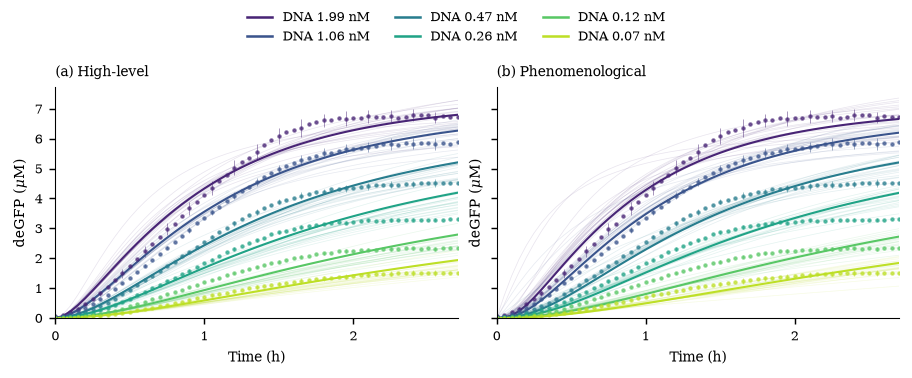

In [20]:
N_PREDICTIVE_DRAWS = 20
FIT_DRAW_SEED = 2026
DATA_ERROR_EVERY = 3
baseline_models = ("Reduced", "Baseline")
baseline_predictions = {name: draw_predictions(name, N_PREDICTIVE_DRAWS, FIT_DRAW_SEED+i)[1]
                        for i, name in enumerate(baseline_models)}
baseline_ymax = 1.05*max(float(np.max(data_mean+data_sd)),
    *(float(np.max(baseline_predictions[name])) for name in baseline_models),
    *(float(np.max(map_trajectories[name])) for name in baseline_models))
fig, axes = plt.subplots(1, 2, figsize=(6.9, 2.8), sharex=True, sharey=True, layout="constrained")
for panel, (name, ax) in enumerate(zip(baseline_models, axes)):
    for c, dna in enumerate(dna_concs_nM):
        ax.errorbar(timepoints/60, data_mean[c], yerr=data_sd[c], color=condition_colors[c],
                    marker="o", markersize=1.5, linestyle="none", elinewidth=.4,
                    errorevery=DATA_ERROR_EVERY, alpha=.65)
        for trajectory in baseline_predictions[name]:
            ax.plot(timepoints/60, trajectory[c], color=condition_colors[c], alpha=.12, linewidth=.4)
        ax.plot(timepoints/60, map_trajectories[name][c], color=condition_colors[c], linewidth=1.15)
    title = "High-level" if name == "Reduced" else "Phenomenological"
    ax.set(title=f"({chr(97+panel)}) {title}", xlabel="Time (h)",
           ylabel=r"deGFP ($\mu$M)", xlim=(0, timepoints[-1]/60), ylim=(0, baseline_ymax), xticks=[0,1,2])
legend = [Line2D([], [], color=condition_colors[c], label=f"DNA {dna:g} nM")
          for c, dna in enumerate(dna_concs_nM)]
fig.legend(handles=legend, loc="outside upper center", ncol=3, frameon=False)
save_figure(fig, "baseline_full_reduced")
figure_settings["baseline_full_reduced"] = dict(posterior_draws=N_PREDICTIVE_DRAWS,
    draw_seed=FIT_DRAW_SEED, error_every=DATA_ERROR_EVERY, shared_ylim=[0,baseline_ymax])


## Marginals and parameter dependence

Select the inferred-parameter pair with the largest absolute Pearson
correlation in log parameters for the phenomenological baseline and for the reduced
model. Use the same phenomenological pair for the guided comparison.

Detailed selected pair: ['ktl', 'kdil']
Reduced selected pair: ['ktl', 'kdil']


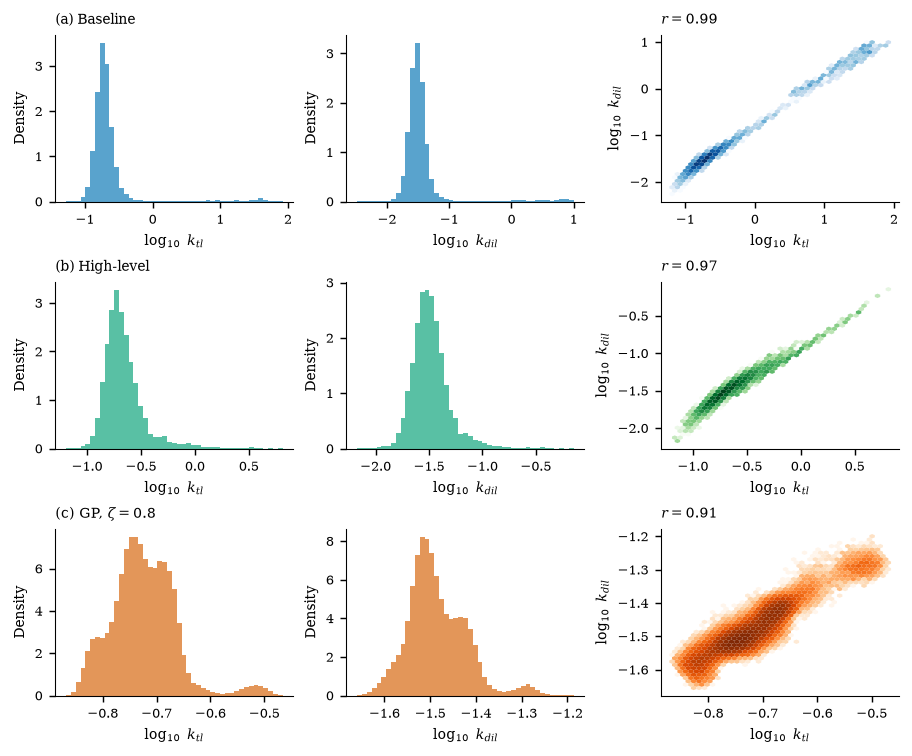

In [21]:
DEPENDENCE_DRAW_SEED = 2026
MAX_DEPENDENCE_DRAWS = 100000
MARGINAL_BINS = 45
HEXBIN_RESOLUTION = 40
log_samples = {name: np.log10(values) for name, values in samples.items()}
log_reduced = np.log10(reduced_samples)
correlations = {name: np.corrcoef(values.T) for name, values in log_samples.items()}
correlations["Reduced"] = np.corrcoef(log_reduced.T)
tri = np.triu_indices(ndim, 1)
winner = int(np.nanargmax(np.abs(correlations["Baseline"][tri])))
detailed_pair = (int(tri[0][winner]), int(tri[1][winner]))
tri_reduced = np.triu_indices(len(reduced_names), 1)
winner = int(np.nanargmax(np.abs(correlations["Reduced"][tri_reduced])))
reduced_pair = (int(tri_reduced[0][winner]), int(tri_reduced[1][winner]))
for name, matrix in correlations.items():
    names = reduced_names if name == "Reduced" else param_names
    pd.DataFrame(matrix, index=names, columns=names).to_csv(OUT / f"{name.lower()}_log_correlations.csv")
print("Detailed selected pair:", [param_names[i] for i in detailed_pair])
print("Reduced selected pair:", [reduced_names[i] for i in reduced_pair])

fig, axes = plt.subplots(3, 3, figsize=(6.9, 5.7), layout="constrained")
rows = [("Baseline", log_samples["Baseline"], detailed_pair, param_names, "Blues"),
        ("Reduced", log_reduced, reduced_pair, reduced_names, "Greens"),
        ("GP-guided 0.8", log_samples["GP-guided 0.8"], detailed_pair, param_names, "Oranges")]
for row, (name, values, pair, names, cmap) in enumerate(rows):
    i, j = pair
    for column, k in enumerate(pair):
        axes[row, column].hist(values[:, k], bins=MARGINAL_BINS, density=True,
            histtype="stepfilled", color=COLORS[name], alpha=.65, linewidth=.6)
        axes[row, column].set(xlabel=r"$\log_{10}$ "+PARAMETER_LABELS[names[k]], ylabel="Density")
    chosen = np.random.default_rng(DEPENDENCE_DRAW_SEED+row).choice(
        len(values), size=min(MAX_DEPENDENCE_DRAWS, len(values)), replace=False)
    axes[row, 2].hexbin(values[chosen, i], values[chosen, j], gridsize=HEXBIN_RESOLUTION,
                       mincnt=1, bins="log", cmap=cmap, linewidths=0, rasterized=True)
    axes[row, 2].set(xlabel=r"$\log_{10}$ "+PARAMETER_LABELS[names[i]],
                     ylabel=r"$\log_{10}$ "+PARAMETER_LABELS[names[j]],
                     title=fr"$r={correlations[name][pair]:.2f}$")
    axes[row, 0].set_title(f"({chr(97+row)}) {DISPLAY_LABELS[name]}", loc="left")
save_figure(fig, "baseline_parameter_dependence")
figure_settings["baseline_parameter_dependence"] = dict(draw_seed=DEPENDENCE_DRAW_SEED,
    maximum_draws=MAX_DEPENDENCE_DRAWS, marginal_bins=MARGINAL_BINS, hexbin_resolution=HEXBIN_RESOLUTION)


## Trained GP evaluated on the inferred posterior tuples

This uses data files from past trained GP to regenerate the figures.

In [22]:
SCREEN_DRAW_SEED = 2026
MAX_SCREEN_DRAWS = 10000
guided = archives["GP-guided 0.8"]
for name in guided_names:
    for archive_key, checkpoint_key in (
        ("gp_training_X", "X_gp"), ("gp_training_targets", "v_gp"),
        ("gp_kernel_constant", "gp_kernel_constant"), ("gp_kernel_length_scale", "gp_kernel_length_scale"),
        ("gp_noise", "gp_noise"), ("gp_validity_scale", "validity_scale"),
        ("gp_epsilon", "epsilon"), ("gp_gamma", "gamma")):
        np.testing.assert_allclose(archives[name][archive_key], gp_archive[checkpoint_key])
def screening_probability(values):
    """Evaluate the fixed GP retention probability for physical parameter tuples."""
    normalized = np.log(values/lower)/np.log(upper/lower)
    mean, sd = trained_gp.predict(normalized, return_std=True)
    return ndtr(mean/np.maximum(sd, 1e-12))


screen_probabilities, screen_parameters = {}, {}
screen_rows, region_rows = [], []
for offset, (name, values) in enumerate(samples.items()):
    rng = np.random.default_rng(SCREEN_DRAW_SEED+offset)
    indices = rng.choice(len(values), size=min(MAX_SCREEN_DRAWS, len(values)), replace=False)
    screen_parameters[name] = values[indices]
    p = screening_probability(values[indices])
    screen_probabilities[name] = p
    for cutoff in screening_levels.values():
        screen_rows.append(dict(method=name, checked_joint_draws=len(p),
            zeta=cutoff, fraction_passing=float(np.mean(p>cutoff))))
    normalized = np.log(values[indices]/lower)/np.log(upper/lower)
    membership = np.all((normalized[:, None] >= gp_archive["region_lower"][None])
                       & (normalized[:, None] <= gp_archive["region_upper"][None]), axis=2)
    for region in range(membership.shape[1]):
        region_rows.append(dict(method=name, region=str(region+1),
                                sampled_draws=int(membership[:, region].sum())))
    region_rows.append(dict(method=name, region="Outside training boxes",
                            sampled_draws=int(np.sum(~membership.any(axis=1)))))
for name in guided_names:
    assert np.all(screen_probabilities[name] > screening_levels[name])
screen_checks = pd.DataFrame(screen_rows)
display(screen_checks)
display(pd.DataFrame(region_rows))
screen_checks.to_csv(OUT / "posterior_screen_check.csv", index=False)
pd.DataFrame(region_rows).to_csv(OUT / "sampled_neighborhood_occupancy.csv", index=False)


,method,checked_joint_draws,zeta,fraction_passing
0,Baseline,10000,0.8,0.0
1,GP-guided 0.8,10000,0.8,1.0


,method,region,sampled_draws
0,Baseline,1,0
1,Baseline,Outside training boxes,10000
2,GP-guided 0.8,1,684
3,GP-guided 0.8,Outside training boxes,9316


## Baseline and GP-guided GFP fits

Show the sampled MAP and 20 posterior draws from each phenomenological model run
against the experimental data.

c:\Users\ayush\.conda\envs\biotools\Lib\site-packages\bioscrape\sbmlutil.py:115: UserWarning: Compartments, UnitDefintions, Events, and some other SBML model components are not recognized by bioscrape. Refer to the bioscrape wiki for more information.
  warnings.warn('Compartments, UnitDefintions, Events, and some other SBML model components are not recognized by bioscrape. ' +


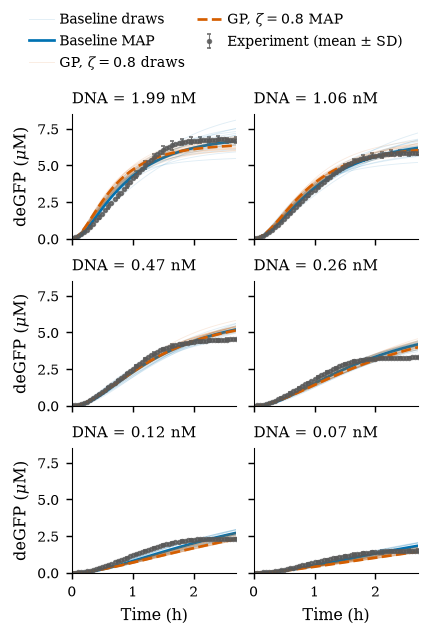

In [23]:
N_PREDICTIVE_DRAWS = 20
FIT_DRAW_SEED = 2026
DATA_ERROR_EVERY = 3
FIT_FIGURE_SIZE = (3.2, 4.8)
FIT_FONT_SIZE = 9
FIT_TITLE_FONT_SIZE = 8.5
FIT_TICK_FONT_SIZE = 8
FIT_LEGEND_FONT_SIZE = 8
posterior_predictions = {}
predictive_sample_indices = {}
for offset, name in enumerate(archives):
    indices, trajectories = draw_predictions(name, N_PREDICTIVE_DRAWS, FIT_DRAW_SEED+offset)
    posterior_predictions[name] = trajectories
    predictive_sample_indices[name] = indices
with plt.rc_context({
    "font.size": FIT_FONT_SIZE, "axes.labelsize": FIT_FONT_SIZE,
    "axes.titlesize": FIT_TITLE_FONT_SIZE, "axes.titlelocation": "left",
    "axes.titleweight": "normal", "xtick.labelsize": FIT_TICK_FONT_SIZE,
    "ytick.labelsize": FIT_TICK_FONT_SIZE,
}):
    fig, axes = plt.subplots(3, 2, figsize=FIT_FIGURE_SIZE, sharex=True, sharey=True, layout="constrained")
    for c, ax in enumerate(axes.flat):
        ax.errorbar(timepoints/60, data_mean[c], yerr=data_sd[c], color=".35",
                    marker="o", markersize=2, linestyle="none", elinewidth=.6,
                    capsize=1, errorevery=DATA_ERROR_EVERY, label="Experiment (mean ± SD)", alpha=.8)
        for name in archives:
            linestyle = LINESTYLES[name]
            for j, trajectory in enumerate(posterior_predictions[name]):
                ax.plot(timepoints/60, trajectory[c], color=COLORS[name], linewidth=.5, alpha=.12,
                        label=DISPLAY_LABELS[name]+" draws" if j == 0 else None)
            ax.plot(timepoints/60, map_trajectories[name][c], linestyle,
                    color=COLORS[name], label=DISPLAY_LABELS[name]+" MAP", linewidth=1.5)
        ax.set(title=f"DNA = {dna_concs_nM[c]:g} nM",
               xlim=(0, timepoints[-1]/60), ylim=(0, None), xticks=[0, 1, 2])
        if c >= 4:
            ax.set_xlabel("Time (h)")
        if c % 2 == 0:
            ax.set_ylabel(r"deGFP ($\mu$M)")
    handles, legend_labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, legend_labels, loc="outside upper center", ncol=2, frameon=False, fontsize=FIT_LEGEND_FONT_SIZE,
               columnspacing=.8, handletextpad=.4, handlelength=1.7)
    save_figure(fig, "gp_vs_baseline_fits")
figure_settings["gp_vs_baseline_fits"] = dict(posterior_draws=N_PREDICTIVE_DRAWS,
    draw_seed=FIT_DRAW_SEED, error_every=DATA_ERROR_EVERY,
    figure_size=FIT_FIGURE_SIZE, font_size=FIT_FONT_SIZE,
    legend_font_size=FIT_LEGEND_FONT_SIZE, layout="3 rows, 2 columns")
predictive_rows = []
for name, trajectories in posterior_predictions.items():
    rmse = np.sqrt(np.mean((trajectories-data_mean[None])**2, axis=2))
    for c, dna in enumerate(dna_concs_nM):
        q = np.quantile(rmse[:, c], [.05, .5, .95])
        predictive_rows.append(dict(method=name, DNA_nM=float(dna), posterior_RMSE_q05=float(q[0]),
                                    posterior_RMSE_median=float(q[1]), posterior_RMSE_q95=float(q[2])))
pd.DataFrame(predictive_rows).to_csv(OUT / "predictive_fit_summary.csv", index=False)


## All DNA-condition trajectories


c:\Users\ayush\.conda\envs\biotools\Lib\site-packages\bioscrape\sbmlutil.py:115: UserWarning: Compartments, UnitDefintions, Events, and some other SBML model components are not recognized by bioscrape. Refer to the bioscrape wiki for more information.
  warnings.warn('Compartments, UnitDefintions, Events, and some other SBML model components are not recognized by bioscrape. ' +


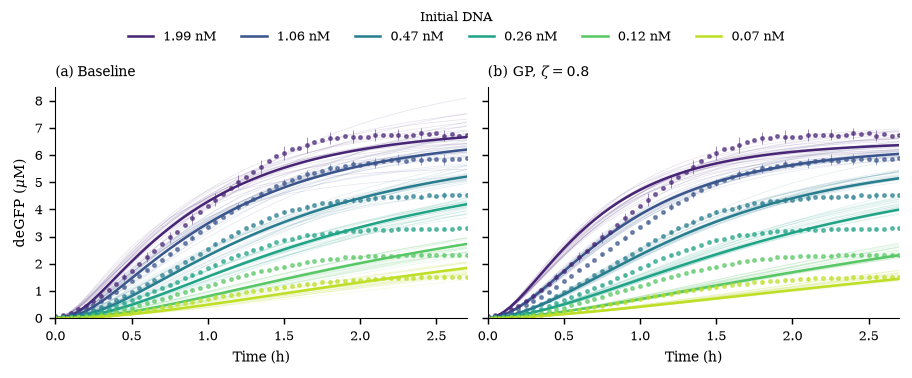

In [24]:
N_PREDICTIVE_DRAWS = 20
FIT_DRAW_SEED = 2026
DATA_ERROR_EVERY = 3
fig, axes = plt.subplots(1, len(archives), figsize=(6.9, 2.8), sharex=True, sharey=True, layout="constrained")
for offset, (name, ax) in enumerate(zip(archives, axes)):
    _, trajectories = draw_predictions(name, N_PREDICTIVE_DRAWS, FIT_DRAW_SEED+offset)
    for c, dna in enumerate(dna_concs_nM):
        ax.errorbar(timepoints/60, data_mean[c], yerr=data_sd[c], color=condition_colors[c],
                    marker="o", markersize=1.8, linestyle="none", elinewidth=.45,
                    errorevery=DATA_ERROR_EVERY, alpha=.6)
        for trajectory in trajectories:
            ax.plot(timepoints/60, trajectory[c], color=condition_colors[c], alpha=.12, linewidth=.45)
        ax.plot(timepoints/60, map_trajectories[name][c], color=condition_colors[c], label=f"{dna:g} nM")
    ax.set(title=f"({chr(97+offset)}) {DISPLAY_LABELS[name]}", xlabel="Time (h)",
           xlim=(0, timepoints[-1]/60), ylim=(0, None))
axes[0].set_ylabel(r"deGFP ($\mu$M)")
handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(handles, legend_labels, title="Initial DNA", frameon=False, ncol=6,
           loc="outside upper center", title_fontsize=7)
save_figure(fig, "all_condition_fits")
figure_settings["all_condition_fits"] = dict(posterior_draws=N_PREDICTIVE_DRAWS,
    draw_seed=FIT_DRAW_SEED, error_every=DATA_ERROR_EVERY)


## Paired phenomenological and mechanistic marginals


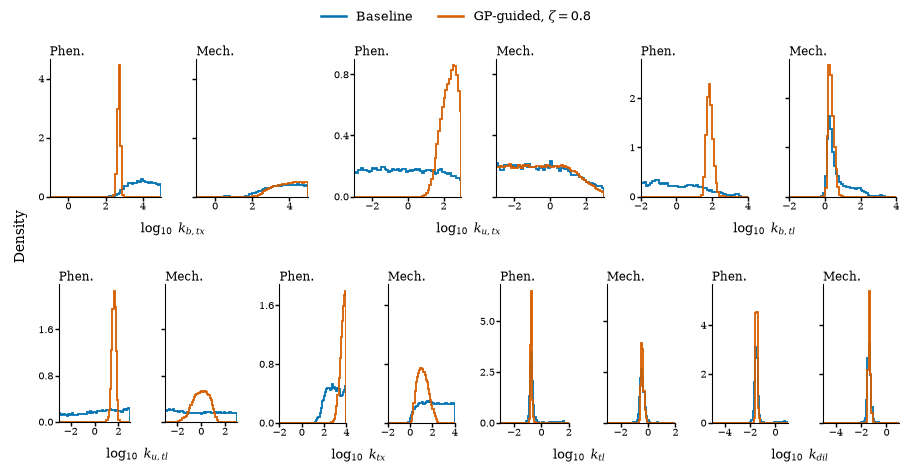

,parameter,normalized_log_Wasserstein
0,kb_tx,0.197875
1,ku_tx,0.400542
2,kb_tl,0.316514
3,ku_tl,0.264522
4,ktx,0.135285
5,ktl,0.022389
6,kdil,0.019633


In [25]:
MARGINAL_BINS = 60
MECHANISTIC_POSTERIOR_WINDOW_STEPS = 10000
MARGINAL_FIGURE_SIZE = (6.9,3.55)
MECHANISTIC_RESULTS = RESULTS_DIR
MECHANISTIC_FILES = {
    "Baseline": MECHANISTIC_RESULTS / "exp3_1_init_baseline_inference_40k_gaussian_batched_1020_2.npz",
    "GP-guided 0.8": MECHANISTIC_RESULTS / "exp3_1_init_gp_inference_zeta_0.8_40k_eps0p5_batched_1020_2.npz",
}
mechanistic_log = {}
for name,path in MECHANISTIC_FILES.items():
    with np.load(path,allow_pickle=False) as record:
        np.testing.assert_array_equal(record["param_names"],param_names)
        assert json.loads(record["prior_json"].item()) == prior
        assert int(record["n_states"]) == 38
        mechanistic_log[name] = np.log10(record["chain"][-MECHANISTIC_POSTERIOR_WINDOW_STEPS:]
                                       .reshape(-1,ndim).copy())
fig = plt.figure(figsize=MARGINAL_FIGURE_SIZE,layout="constrained")
row_figures = fig.subfigures(2,1,hspace=.10)
parameter_index = 0
for row,count in zip(row_figures,(3,4)):
    groups = row.subfigures(1,count,wspace=.05)
    for group in groups:
        i = parameter_index
        pair = group.subplots(1,2,sharex=True,sharey=True,gridspec_kw={"wspace":.07})
        bins = np.linspace(np.log10(lower[i]),np.log10(upper[i]),MARGINAL_BINS+1)
        for ax,values,title in zip(pair,(log_samples,mechanistic_log),("Phen.","Mech.")):
            for method in archives:
                ax.hist(values[method][:,i],bins=bins,density=True,histtype="step",
                        linewidth=1.0,color=COLORS[method])
            ax.set_title(title,fontsize=6.5,pad=2)
            ax.set_xlim(bins[0],bins[-1])
            ax.tick_params(labelsize=5.5,length=2,pad=1)
            ax.xaxis.set_major_locator(plt.MaxNLocator(3))
            ax.yaxis.set_major_locator(plt.MaxNLocator(3))
        group.supxlabel(r"$\log_{10}$ "+PARAMETER_LABELS[param_names[i]],fontsize=7)
        parameter_index += 1
fig.supylabel("Density",fontsize=8)
legend = [Line2D([],[],color=COLORS["Baseline"],label="Baseline"),
          Line2D([],[],color=COLORS["GP-guided 0.8"],label=r"GP-guided, $\zeta=0.8$")]
fig.legend(handles=legend,frameon=False,ncol=2,loc="outside upper center",fontsize=7)
save_figure(fig,"gp_vs_baseline_marginals")
figure_settings["gp_vs_baseline_marginals"] = dict(
    parameter_groups_per_row=[3,4],within_group_order=["phenomenological","mechanistic"],
    figure_size_inches=list(MARGINAL_FIGURE_SIZE),bins=MARGINAL_BINS,
    phenomenological_window_steps=POSTERIOR_WINDOW_STEPS,
    mechanistic_window_steps=MECHANISTIC_POSTERIOR_WINDOW_STEPS,
    mechanistic_sources={str(path):sha256(path) for path in MECHANISTIC_FILES.values()})
distance_rows = []
for i,parameter in enumerate(param_names):
    normalized = [np.log(values[:,i]/lower[i])/np.log(upper[i]/lower[i]) for values in samples.values()]
    distance_rows.append(dict(parameter=parameter,normalized_log_Wasserstein=wasserstein_distance(*normalized)))
distances = pd.DataFrame(distance_rows)
distances.to_csv(OUT/"posterior_distances.csv",index=False)
display(distances)


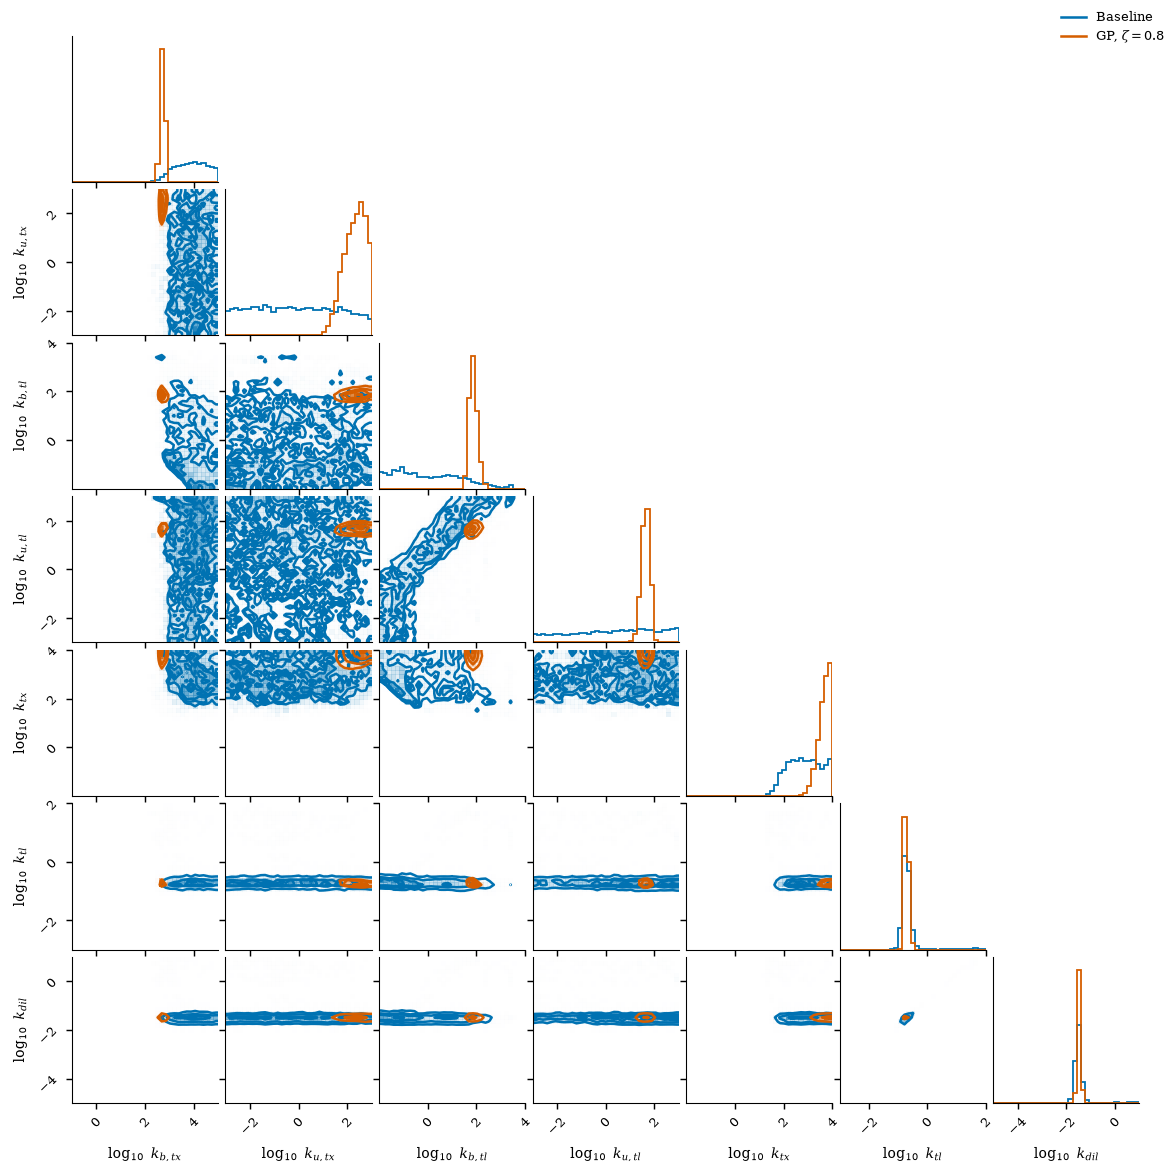

In [26]:
MAX_CORNER_DRAWS = 20000
CORNER_DRAW_SEED = 2026
CORNER_BINS = 35
corner_figure = None
corner_labels = [r"$\log_{10}$ "+label for label in labels]
for offset, name in enumerate(archives):
    rng = np.random.default_rng(CORNER_DRAW_SEED+offset)
    indices = rng.choice(len(samples[name]), size=min(MAX_CORNER_DRAWS, len(samples[name])), replace=False)
    corner_figure = corner.corner(np.log10(samples[name][indices]), fig=corner_figure,
        labels=corner_labels, bins=CORNER_BINS,
        range=[(np.log10(lo), np.log10(hi)) for lo, hi in zip(lower, upper)],
        color=COLORS[name], plot_datapoints=False, fill_contours=False,
        hist_kwargs={"density": True, "linewidth": 1.0},
        label_kwargs={"fontsize": 8}, max_n_ticks=3)
corner_figure.set_size_inches(9, 9)
corner_figure.legend([Line2D([0], [0], color=COLORS[name]) for name in archives],
                     [DISPLAY_LABELS[name] for name in archives], frameon=False, loc="upper right")
save_figure(corner_figure, "detailed_corner_comparison")
figure_settings["detailed_corner_comparison"] = dict(maximum_draws=MAX_CORNER_DRAWS,
    draw_seed=CORNER_DRAW_SEED, bins=CORNER_BINS)


## Computational performance


In [27]:
DETAILED_SECONDS = {name: float(a["runtime_seconds"]) for name, a in archives.items()}
REDUCED_SECONDS = float(reduced_archive["runtime_seconds"])
GP_TRAINING_SECONDS = float(guided["gp_training_seconds"])
np.testing.assert_allclose(guided["reduced_inference_seconds"], REDUCED_SECONDS)
np.testing.assert_allclose(GP_TRAINING_SECONDS, gp_timing["GP_construction_seconds"])
np.testing.assert_allclose(GP_TRAINING_SECONDS, gp_archive["gp_training_seconds"])
MCMC_REDUCTION_PCT = {name: 100*(1-DETAILED_SECONDS[name]/DETAILED_SECONDS["Baseline"])
                      for name in guided_names}
stage_times = pd.DataFrame({name: [
    np.nan if name == "Baseline" else REDUCED_SECONDS/60,
    np.nan if name == "Baseline" else GP_TRAINING_SECONDS/60,
    DETAILED_SECONDS[name]/60] for name in archives},
    index=["Reduced inference (min)", "GP construction (min)", "MCMC inference (min)"])
display(stage_times)
stage_times.to_csv(OUT / "stage_times_minutes.csv", index_label="stage")

efficiency = pd.DataFrame(index=param_names)
performance = {}
for name, archive in archives.items():
    detailed_minutes = DETAILED_SECONDS[name]/60
    efficiency[name+"_tau_full_postburn_steps"] = archive["tau"]
    efficiency[name+"_ESS_full_postburn"] = archive["ess"]
    efficiency[name+"_ESS_per_detailed_min"] = archive["ess"]/detailed_minutes
    performance[name] = {
        "MCMC inference (min)": detailed_minutes,
        "MCMC time reduction (%)": 0. if name == "Baseline" else MCMC_REDUCTION_PCT[name],
        "Mean acceptance fraction": float(archive["acceptance_fraction"].mean()),
        "Mean MAP RMSE (uM)": float(fit_table[name+"_MAP_RMSE_uM"].mean()),
        "Pooled MAP RMSE (uM)": float(np.sqrt(np.mean((map_trajectories[name]-data_mean)**2))),
        "Maximum condition MAP RMSE (uM)": float(fit_table[name+"_MAP_RMSE_uM"].max()),
        "MAP residual norm": float(np.linalg.norm(experimental-map_trajectories[name][:, None, :])),
        "Minimum saved ESS": float(archive["ess"].min()),
        "Maximum saved tau (steps)": float(archive["tau"].max()),
        "Minimum ESS per detailed minute": float(archive["ess"].min()/detailed_minutes),
        "Full postburn steps / maximum tau": float((int(archive["nsteps"])-int(archive["burn"]))/archive["tau"].max()),
    }
for name in guided_names:
    efficiency[name+"_ESS_per_detailed_min_change_pct"] = 100*(
        efficiency[name+"_ESS_per_detailed_min"]/efficiency["Baseline_ESS_per_detailed_min"]-1)
performance = pd.DataFrame(performance)
display(performance)
display(efficiency)
performance.to_csv(OUT / "performance.csv", index_label="metric")
efficiency.to_csv(OUT / "sampling_efficiency.csv", index_label="parameter")
for name in guided_names:
    print(f"{name}: MCMC time reduction {MCMC_REDUCTION_PCT[name]:.2f}%")
print("GP construction timing scope:", gp_timing["timing_scope"])

proposal_counts = pd.DataFrame({name: {key: float(archives[name][key]) for key in (
    "n_proposals_evaluated", "n_parameter_prior_rejected", "gp_screening_proposals",
    "gp_screening_rejected", "n_likelihood_evaluations", "gp_screening_seconds")}
    for name in guided_names})
proposal_counts.loc["GP rejection of ordinary-prior-valid proposals (%)"] = (
    100*proposal_counts.loc["gp_screening_rejected"]/proposal_counts.loc["gp_screening_proposals"])
proposal_counts.loc["GP filtering fraction of detailed time (%)"] = [
    100*proposal_counts.loc["gp_screening_seconds", name]/DETAILED_SECONDS[name] for name in guided_names]
display(proposal_counts)
proposal_counts.to_csv(OUT / "proposal_screening_counts.csv", index_label="metric")


,Baseline,GP-guided 0.8
Reduced inference (min),NaN,6.643030
GP construction (min),NaN,2.940936
MCMC inference (min),92.384831,84.977858


,Baseline,GP-guided 0.8
MCMC inference (min),92.384831,84.977858
MCMC time reduction (%),0.000000,8.017520
Mean acceptance fraction,0.065723,0.247221
Mean MAP RMSE (uM),0.271721,0.360729
Pooled MAP RMSE (uM),0.284514,0.376238
Maximum condition MAP RMSE (uM),0.360805,0.547182
MAP residual norm,9.433960,12.206579
Minimum saved ESS,3570.599584,15219.340312
Maximum saved tau (steps),2509.382469,588.724598
Minimum ESS per detailed minute,38.649198,179.097716


,Baseline_tau_full_postburn_steps,Baseline_ESS_full_postburn,Baseline_ESS_per_detailed_min,GP-guided 0.8_tau_full_postburn_steps,GP-guided 0.8_ESS_full_postburn,GP-guided 0.8_ESS_per_detailed_min,GP-guided 0.8_ESS_per_detailed_min_change_pct
kb_tx,2274.474360,3939.371732,42.640894,349.847277,25611.175504,301.386456,606.801455
ku_tx,1689.129720,5304.506748,57.417508,365.657649,24503.794802,288.355053,402.207539
kb_tl,2509.382469,3570.599584,38.649198,448.991650,19955.827700,234.835616,507.607999
ku_tl,2178.312325,4113.276089,44.523284,332.863112,26917.972178,316.764540,611.458162
ktx,2180.072119,4109.955776,44.487344,321.641680,27857.086214,327.815820,636.874328
ktl,1838.416280,4873.760147,52.754983,588.724598,15219.340312,179.097716,239.489669
kdil,1789.791152,5006.170688,54.188233,541.576208,16544.301376,194.689555,259.283826


GP-guided 0.8: MCMC time reduction 8.02%
GP construction timing scope: fresh deterministic seed search, 100 new local probes, initial fit, 200 GP-MPM acquisitions


,GP-guided 0.8
n_proposals_evaluated,1.024026e+07
n_parameter_prior_rejected,2.387348e+06
gp_screening_proposals,7.852908e+06
gp_screening_rejected,2.486104e+06
n_likelihood_evaluations,5.366804e+06
gp_screening_seconds,1.207040e+02
GP rejection of ordinary-prior-valid proposals (%),3.165839e+01
GP filtering fraction of detailed time (%),2.367362e+00


## Publication tables and source record

We save data for: percentage reductions, one-time setup costs, MAP fit
errors, sampling diagnostics, and other model-level metrics.

In [28]:
def table_value(value, precision=2):
    """Format a value for a publication table or LaTeX macro."""
    return "--" if pd.isna(value) else f"{value:.{precision}f}"


guided_name = "GP-guided 0.8"
table_lines = [r"\begin{tabular}{lrr}", r"\toprule", "Metric & Baseline & GP-guided "+chr(92)*2, r"\midrule"]
for stage, row in stage_times.iterrows():
    table_lines.append(stage+" & "+" & ".join(table_value(row[name]) for name in archives)+" "+chr(92)*2)
for key, title in (("Mean acceptance fraction", "Mean acceptance fraction"),
                   ("Mean MAP RMSE (uM)", r"Mean MAP RMSE ($\mu$M)"),
                   ("Minimum ESS per detailed minute", r"Minimum $\widehat{\mathrm{ESS}}_i$/min")):
    table_lines.append(title+" & "+" & ".join(table_value(performance.loc[key,name],3) for name in archives)+" "+chr(92)*2)
table_lines.append(r"MCMC time reduction (\%) & 0 & "
                   +table_value(MCMC_REDUCTION_PCT[guided_name])+" "+chr(92)*2)

table_lines += [r"\bottomrule", r"\end{tabular}"]
(OUT/"performance_table.tex").write_text("\n".join(table_lines)+"\n",encoding="utf-8")
final_error = training_comparison[training_comparison.additional_evaluations==ACQUISITION_BUDGET].set_index("method")
validation = local_validation.set_index("zeta").loc[.8]
numbers = {
    "GeneHPMCMCTimeReductionPct": MCMC_REDUCTION_PCT[guided_name],
    "GeneHPMCMCMinutesSaved": (DETAILED_SECONDS["Baseline"]-DETAILED_SECONDS[guided_name])/60,
    "GeneHPBaselineMinutes": DETAILED_SECONDS["Baseline"]/60,
    "GeneHPGuidedMinutes": DETAILED_SECONDS[guided_name]/60,
    "GeneHPReducedMinutes": REDUCED_SECONDS/60,
    "GeneHPGPTrainingMinutes": GP_TRAINING_SECONDS/60,
    "GeneHPReducedRMSE": float(fit_table["Reduced_MAP_RMSE_uM"].mean()),
    "GeneHPBaselineRMSE": float(fit_table["Baseline_MAP_RMSE_uM"].mean()),
    "GeneHPGuidedRMSE": float(fit_table[guided_name+"_MAP_RMSE_uM"].mean()),
    "GeneHPWalkers": int(archives["Baseline"]["nwalkers"]),
    "GeneHPSteps": int(archives["Baseline"]["nsteps"]),
    "GeneHPBurn": int(archives["Baseline"]["burn"]),
    "GeneHPBaselineExcludedPct": 100*float(np.mean(screen_probabilities["Baseline"]<=.8)),
    "GeneHPGPBalancedErrorPct": 100*float(final_error.loc["GP-MPM","balanced_error"]),
    "GeneHPGPStrictBalancedErrorPct": 50*(2-float(validation["compatible_kept"]/validation["compatible_total"])-float(validation["incompatible_rejected"]/validation["incompatible_total"])),
    "GeneHPRandomBalancedErrorPct": 100*float(final_error.loc["Uniform random","balanced_error"]),
    "GeneHPGPCompatibleRetainedPct": 100*float(validation.compatible_kept/validation.compatible_total),
    "GeneHPGPIncompatibleRejectedPct": 100*float(validation.incompatible_rejected/validation.incompatible_total),
    "GeneHPGPProposalRejectedPct": float(proposal_counts.loc["GP rejection of ordinary-prior-valid proposals (%)",guided_name]),
    "GeneHPGPScreeningMinutes": float(guided["gp_screening_seconds"])/60,
}
macro_lines = []
for name,value in numbers.items():
    precision = 0 if name.endswith(("Walkers","Steps","Burn")) else (3 if name.endswith("RMSE") else 2)
    macro_lines.append(chr(92)+"newcommand{"+chr(92)+name+"}{"+table_value(value,precision)+"}")
for command,parameter in (("GeneHPPairFirst",param_names[detailed_pair[0]]),
                          ("GeneHPPairSecond",param_names[detailed_pair[1]])):
    macro_lines.append(chr(92)+"newcommand{"+chr(92)+command+"}{"+PARAMETER_LABELS[parameter]+"}")
(OUT/"numbers.tex").write_text("\n".join(macro_lines)+"\n",encoding="utf-8")
source_paths = [BASELINE_FILE,*GUIDED_FILES.values(),REDUCED_FILE,MODEL_FILE,REDUCED_MODEL_FILE,
               DATA_FILE,GP_FILE,GP_RANDOM_FILE,GP_INPUT_FILE,TRAINING_HISTORY_FILE,TIMING_FILE,TEST_FILE,*MECHANISTIC_FILES.values()]
manifest = dict(sources={str(path):sha256(path) for path in source_paths},
    python=platform.python_version(),
    packages={package:importlib.metadata.version(package) for package in
              ("numpy","scipy","pandas","matplotlib","scikit-learn","bioscrape","emcee","corner")},
    run_tag=RUN_TAG, mapping="GP_hp", model_states=9, inferred_parameters=param_names,prior=prior,
    fixed_parameters=fixed_detailed,fixed_reduced_parameters=fixed_reduced,
    concentration_unit="uM",time_unit="min",DNA_NM_TO_UM=DNA_NM_TO_UM,
    initialization={name:dict(mode=a["initialization_mode"].item(),
                             centre=a["initialization_center"].tolist()) for name,a in archives.items()},
    inference_settings={name:{key:int(a[key]) for key in
        ("nsteps","nwalkers","burn","n_processes","random_seed")} for name,a in archives.items()},
    posterior_window_steps=POSTERIOR_WINDOW_STEPS,reduced_posterior_window_steps=REDUCED_POSTERIOR_WINDOW_STEPS,
    sampled_MAP_scope="maximum saved log posterior over all post-burn joint tuples",
    sampled_MAP_locations=map_locations,
    reduced_MAP_location=dict(step=int(reduced_map_step),walker=int(reduced_map_walker)),
    GP_settings=json.loads(gp_archive["settings_json"].item()),GP_timing_record=gp_timing,
    GP_epsilon_uM=epsilon,GP_gamma=gamma,GP_screening_levels=screening_levels,
    MCMC_time_reduction_pct=MCMC_REDUCTION_PCT,
    detailed_inference_seconds=DETAILED_SECONDS,reduced_inference_seconds=REDUCED_SECONDS,
    GP_training_seconds=GP_TRAINING_SECONDS,
    runtime_comparison_scope="MCMC elapsed time",
    one_time_setup_seconds=dict(reduced_inference=REDUCED_SECONDS, GP_training=GP_TRAINING_SECONDS),
    percentage_definition="100*(baseline_MCMC_time-guided_MCMC_time)/baseline_MCMC_time",
    figure_settings=figure_settings,requested_hardware=dict(cluster="pinnacles",CPU_constraint="6330",CPUs=32))
(OUT/"provenance.json").write_text(json.dumps(manifest,indent=2)+"\n",encoding="utf-8")


14514

## Run inference -- RECOMMENDED TO RUN ON HPC


### High-level inference

Fit the two-state model using the existing Bioscrape inference workflow.


In [ ]:
from hierarch_inf.gene_expression import high_level

high_level.DATA_FILE = DATA_FILE
high_level.main()

### Reduced-posterior trajectories



In [30]:
RUN_TAG = "1020"
HPC_REDUCED_RESULT_FILE = RESULTS_DIR / f"reduced_model_inference_10k_{RUN_TAG}.npz"

with np.load(HPC_REDUCED_RESULT_FILE, allow_pickle=False) as archive:
    hpc_reduced_chain = archive["chain"]
    hpc_reduced_log_prob = archive["log_prob"]
    hpc_reduced_burn = int(archive["burn"])
    ENZYME_TOTALS = json.loads(archive["enzyme_totals_json"].item())
    params_to_estimate_reduced = archive["param_names"].tolist()
    fixed_reduced_parameters = json.loads(archive["fixed_parameters_json"].item())
    FIXED_RNA_PARAMETERS = json.loads(archive["fixed_detailed_parameters_json"].item())
    dna_concs = archive["dna_concs"]
    timepoints = archive["timepoints"]
    experimental_mean_trajectories = archive["experimental_mean_trajectories"]
    DNA_NM_TO_UM = float(archive["DNA_NM_TO_UM"])
    reduced_inference_seconds = float(archive["runtime_seconds"])
    hpc_reduced_prior_json = archive["prior_json"]

M_reduced = Model(sbml_filename=str(MODEL_DIR / "gfp_reduced_TX.xml"))
M_reduced.set_params({**fixed_reduced_parameters, **ENZYME_TOTALS})
print("Loaded:", HPC_REDUCED_RESULT_FILE)
print("HPC chain shape (steps, walkers, parameters):", hpc_reduced_chain.shape)
print("Fixed RNA degradation parameters:", fixed_reduced_parameters)
print("Reduced inference time (minutes):", reduced_inference_seconds / 60)


Loaded: c:\Users\ayush\Box\Research\hierarchical-validation-id\hierarch-inf\examples\results\reduced_model_inference_10k_1020.npz
HPC chain shape (steps, walkers, parameters): (10000, 64, 5)
Fixed RNA degradation parameters: {'K_2': 0.11000000000000001, 'kdeg': 0.1}
Reduced inference time (minutes): 6.643030077498406


c:\Users\ayush\.conda\envs\biotools\Lib\site-packages\bioscrape\sbmlutil.py:115: UserWarning: Compartments, UnitDefintions, Events, and some other SBML model components are not recognized by bioscrape. Refer to the bioscrape wiki for more information.
  warnings.warn('Compartments, UnitDefintions, Events, and some other SBML model components are not recognized by bioscrape. ' +


In [31]:
N_REDUCED_POSTERIOR_STEPS = 5000
assert len(hpc_reduced_chain)-N_REDUCED_POSTERIOR_STEPS >= hpc_reduced_burn
N_REDUCED_POSTERIOR_SAMPLES = 3200
POSTERIOR_RANDOM_SEED = 2026

posterior_window = hpc_reduced_chain[-N_REDUCED_POSTERIOR_STEPS:].reshape(
    -1, len(params_to_estimate_reduced)
)
posterior_rng = np.random.default_rng(POSTERIOR_RANDOM_SEED)
selected_rows = posterior_rng.choice(
    len(posterior_window), size=N_REDUCED_POSTERIOR_SAMPLES, replace=False
)
reduced_posterior_samples = posterior_window[selected_rows]
window_start_step = len(hpc_reduced_chain) - N_REDUCED_POSTERIOR_STEPS
reduced_sample_step_indices = window_start_step + selected_rows // hpc_reduced_chain.shape[1]
reduced_sample_walker_indices = selected_rows % hpc_reduced_chain.shape[1]

print("HPC ensemble steps:", window_start_step, "to", len(hpc_reduced_chain) - 1)
print("Selected parameter tuples:", reduced_posterior_samples.shape)

import time
GP_PREPARATION_START = time.perf_counter()


HPC ensemble steps: 5000 to 9999
Selected parameter tuples: (3200, 5)


In [32]:
reduced_posterior_trajectories = np.zeros(
    (
        len(reduced_posterior_samples),
        len(dna_concs),
        len(timepoints),
    ),
    dtype=float,
)

for s, theta in enumerate(
    reduced_posterior_samples
):

    theta_dict = dict(
        zip(
            params_to_estimate_reduced,
            theta,
        )
    )

    for c, dna in enumerate(
        dna_concs
    ):

        M_reduced.set_params(
            {
                **theta_dict,
                "DNA": float(dna),
            }
        )

        M_reduced.set_species(
            {
                "mRNA": 0.0,
                "GFP": 0.0,
            }
        )

        simulation = py_simulate_model(
            timepoints,
            Model=M_reduced,
        )

        reduced_posterior_trajectories[
            s,
            c,
            :
        ] = simulation[
            "GFP"
        ].to_numpy(dtype=float)

    if (s + 1) % 500 == 0:
        print(
            f"{s + 1} / "
            f"{len(reduced_posterior_samples)}"
        )

print(
    "Reduced trajectory array:",
    reduced_posterior_trajectories.shape
)


500 / 3200
1000 / 3200
1500 / 3200
2000 / 3200
2500 / 3200
3000 / 3200
Reduced trajectory array: (3200, 6, 55)


In [33]:
reduced_data_difference = reduced_posterior_trajectories - experimental_mean_trajectories[None, :, :]
reduced_data_rmse_by_condition = np.sqrt(np.mean(reduced_data_difference ** 2, axis=2))
D_data_reduced_posterior = np.mean(reduced_data_rmse_by_condition, axis=1)

print("Reduced posterior discrepancy from experimental data")
print("min:   ", np.min(D_data_reduced_posterior))
print("median:", np.median(D_data_reduced_posterior))
print("90%:   ", np.quantile(D_data_reduced_posterior, 0.90))
print("95%:   ", np.quantile(D_data_reduced_posterior, 0.95))
print("99%:   ", np.quantile(D_data_reduced_posterior, 0.99))
print("max:   ", np.max(D_data_reduced_posterior))


Reduced posterior discrepancy from experimental data
min:    0.23632754586103377
median: 0.28748167501718674
90%:    0.3558673344764965
95%:    0.38335286330610685
99%:    0.4387836778031324
max:    0.6057361245807171


In [34]:
import hashlib

RUN_TAG = "1020"
GP_INPUT_FILE = RESULTS_DIR / f"gp_hierarchid_inputs_{RUN_TAG}.npz"
gp_preparation_seconds = time.perf_counter()-GP_PREPARATION_START
np.savez_compressed(
    GP_INPUT_FILE,
    concentration_unit=np.array("uM"), DNA_NM_TO_UM=DNA_NM_TO_UM,
    fixed_reduced_parameters_json=np.array(json.dumps(fixed_reduced_parameters)),
    enzyme_totals_json=np.array(json.dumps(ENZYME_TOTALS)),
    reduced_posterior_trajectories=reduced_posterior_trajectories,
    reduced_posterior_samples=reduced_posterior_samples,
    reduced_param_names=np.array(params_to_estimate_reduced),
    dna_concs=dna_concs, dna_concs_nM=dna_concs/DNA_NM_TO_UM,
    timepoints=timepoints,
    D_data_reduced_posterior=D_data_reduced_posterior,
    experimental_mean_trajectories=experimental_mean_trajectories,
    reduced_posterior_steps=N_REDUCED_POSTERIOR_STEPS,
    n_reduced_posterior_samples=N_REDUCED_POSTERIOR_SAMPLES,
    posterior_random_seed=POSTERIOR_RANDOM_SEED,
    reduced_sample_step_indices=reduced_sample_step_indices,
    reduced_sample_walker_indices=reduced_sample_walker_indices,
    reduced_inference_seconds=reduced_inference_seconds,
    reduced_gp_preparation_seconds=gp_preparation_seconds,
    reduced_prior_json=hpc_reduced_prior_json,
    reduced_result_file=np.array(str(HPC_REDUCED_RESULT_FILE)),
    reduced_result_SHA256=np.array(hashlib.sha256(HPC_REDUCED_RESULT_FILE.read_bytes()).hexdigest()),
    reduced_model_file=np.array(str(MODEL_DIR / "gfp_reduced_TX.xml")),
    reduced_model_SHA256=np.array(hashlib.sha256((MODEL_DIR / "gfp_reduced_TX.xml").read_bytes()).hexdigest()),
)
print("Saved GP inputs:", GP_INPUT_FILE)
print("Reduced inference (minutes):", reduced_inference_seconds/60)
print("GP trajectory preparation (seconds):", gp_preparation_seconds)


Saved GP inputs: c:\Users\ayush\Box\Research\hierarchical-validation-id\hierarch-inf\examples\results\gp_hierarchid_inputs_1020.npz
Reduced inference (minutes): 6.643030077498406
GP trajectory preparation (seconds): 141.66457410005387


### Behavioral GP learning

Learn GP_hp for the nine-state model.


In [35]:
import os
for variable in ("OMP_NUM_THREADS", "MKL_NUM_THREADS",
                 "OPENBLAS_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[variable] = "1"

from pathlib import Path
import time
import json
import platform
import hashlib


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from bioscrape.types import Model
from bioscrape.simulator import py_simulate_model

plt.rcParams.update({
    "font.family": "serif", "font.serif": ["DejaVu Serif"],
    "mathtext.fontset": "dejavuserif", "font.size": 9,
    "axes.labelsize": 9, "axes.titlesize": 9, "legend.fontsize": 8,
    "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.spines.top": False, "axes.spines.right": False,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})


In [36]:
REPO_ROOT = next(
    parent for parent in (Path.cwd(), *Path.cwd().parents)
    if (parent / "hierarch_inf").is_dir()
)
APPLICATION_DIR = REPO_ROOT / "examples"
MODEL_DIR = APPLICATION_DIR / "models"
RESULTS_DIR = APPLICATION_DIR / "results"
RUN_TAG = "1020"
GP_INPUT_FILE = RESULTS_DIR / "gp_hierarchid_inputs_1020.npz"

DATA_DIR = APPLICATION_DIR / "data"


In [37]:
RUN_TAG = "1020"
GP_INPUT_FILE = RESULTS_DIR / "gp_hierarchid_inputs_1020.npz"
import importlib
from hierarch_inf.gene_expression import phenomenological as p_setup
p_setup = importlib.reload(p_setup)
gp_inputs = np.load(GP_INPUT_FILE, allow_pickle=False)
assert gp_inputs["concentration_unit"].item() == "uM"
assert float(gp_inputs["DNA_NM_TO_UM"]) == 1e-3
reduced_posterior_trajectories = gp_inputs["reduced_posterior_trajectories"]
dna_concs, timepoints = gp_inputs["dna_concs"], gp_inputs["timepoints"]
params_to_estimate_detailed = list(p_setup.params_to_estimate)
lower_bounds_detailed = np.array([p_setup.prior[p][1] for p in params_to_estimate_detailed])
upper_bounds_detailed = np.array([p_setup.prior[p][2] for p in params_to_estimate_detailed])
fixed_detailed_parameters = dict(p_setup.FIXED_PARAMETERS)
fixed_reduced_parameters = json.loads(gp_inputs["fixed_reduced_parameters_json"].item())
print("High-level inputs:", GP_INPUT_FILE)
print("Reduced HPC source:", gp_inputs["reduced_result_file"].item())
print("Reduced trajectories:", reduced_posterior_trajectories.shape)
print("Phenomenological inferred parameters:", params_to_estimate_detailed)
print("Prior bounds:", p_setup.prior)


High-level inputs: c:\Users\ayush\Box\Research\hierarchical-validation-id\hierarch-inf\examples\results\gp_hierarchid_inputs_1020.npz
Reduced HPC source: c:\Users\ayush\Box\Research\hierarchical-validation-id\hierarch-inf\examples\results\reduced_model_inference_10k_1020.npz
Reduced trajectories: (3200, 6, 55)
Phenomenological inferred parameters: ['kb_tx', 'ku_tx', 'kb_tl', 'ku_tl', 'ktx', 'ktl', 'kdil']
Prior bounds: {'kb_tx': ['log-uniform', 0.1, 100000.0], 'ku_tx': ['log-uniform', 0.001, 1000.0], 'kb_tl': ['log-uniform', 0.01, 10000.0], 'ku_tl': ['log-uniform', 0.001, 1000.0], 'ktx': ['log-uniform', 0.01, 10000.0], 'ktl': ['log-uniform', 0.001, 100.0], 'kdil': ['log-uniform', 1e-05, 10.0]}


In [38]:
CLEAN_SBML = MODEL_DIR / "gfp_expression_bioscrape.xml"
M = Model(sbml_filename=str(CLEAN_SBML))
M.set_params(fixed_detailed_parameters)
assert len(M.get_species_dictionary()) == 9
assert set(params_to_estimate_detailed) | set(fixed_detailed_parameters) == set(M.get_parameter_dictionary())
print("Phenomenological model:", CLEAN_SBML, "; states:", len(M.get_species_dictionary()))


Phenomenological model: c:\Users\ayush\Box\Research\hierarchical-validation-id\hierarch-inf\examples\models\gfp_expression_bioscrape.xml ; states: 9


In [39]:
dim_beta = len(
    params_to_estimate_detailed
)

log_lower_bounds = np.log(
    lower_bounds_detailed
)

log_upper_bounds = np.log(
    upper_bounds_detailed
)

print(
    "GP parameter dimension:",
    dim_beta
)


GP parameter dimension: 7


### Compatibility settings

Each discrepancy is the average of the six condition-wise trajectory RMSEs.
For the M reduced-posterior trajectories, the compatibility margin is

$v(\theta)=\epsilon-d_{(\lceil\gamma M\rceil)}(\theta),$

where the subscript denotes the ordered trajectory discrepancy. 

In [40]:
epsilon = 0.5
gamma = 0.5
print("epsilon:", epsilon, "µM; gamma:", gamma)


epsilon: 0.5 µM; gamma: 0.5


In [41]:
from sklearn.base import clone
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, RBF
from scipy.special import erfc, ndtr
from scipy.linalg import solve_triangular
from scipy.spatial.distance import cdist
from scipy.stats import qmc
import warnings
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)


GP_INITIAL_LENGTH_SCALE = 0.25
GP_LENGTH_SCALE_BOUNDS = (0.01, 10.0)
GP_CONSTANT_BOUNDS = (1e-3, 1e3)
GP_NOISE = 1e-8
GP_OPTIMIZER_RESTARTS = 5
GP_SCREENING_LEVEL = 0.8

GP_OPTIMIZER_SEED = 123

kernel = ConstantKernel(1.0, constant_value_bounds=GP_CONSTANT_BOUNDS) * RBF(
    length_scale=np.full(dim_beta, GP_INITIAL_LENGTH_SCALE),
    length_scale_bounds=GP_LENGTH_SCALE_BOUNDS,
)


## Find a compatible centre through a fresh deterministic search

Our approach to find compatible points in the search:

1. Evaluate a fixed Sobol design across the log-prior box. 
2. Refine its best tuple with deterministic bounded Powell search. 
3. Note that every label is calculated from nine-state trajectories and the current high-level posterior. 
4. Select the smallest discrepancy tuple and define one neighborhood around it in normalized log coordinates.
5. Retain the centre plus 28 maximally spaced search tuples in this neighborhood
as seed observations. Add 100 new local probes for a 129-point initial design.


In [42]:
N_REGIONS = 1
REGION_HALF_WIDTH = 0.04
N_SEED_TRAINING_POINTS = 29
SEED_SOBOL_POWER = 10
SEED_LOCAL_EVALUATIONS = 1024
SEED_LOCAL_XTOL = 1e-4
SEED_LOCAL_FTOL = 1e-5
SEED_SOURCE_FILE = DATA_DIR / "gp_hp_seed_1020.npz"
seed_start = time.perf_counter()
seed_rows = {}


def compute_point(x, purpose):
    """Simulate a parameter tuple and measure its reduced-posterior discrepancy."""
    x = np.asarray(x, dtype=float)
    beta = np.exp(log_lower_bounds+x*(log_upper_bounds-log_lower_bounds))
    M.set_params(dict(zip(params_to_estimate_detailed, beta)))
    trajectories = np.empty((len(dna_concs), len(timepoints)))
    for c, dna in enumerate(dna_concs):
        M.set_species({"DNA": float(dna)})
        trajectories[c] = py_simulate_model(timepoints, Model=M)["GFP"].to_numpy(dtype=float)
    distances = np.sqrt(np.mean((reduced_posterior_trajectories-trajectories[None])**2, axis=2)).mean(axis=1)
    rank = int(np.ceil(gamma*len(distances)))-1
    rho = float(np.partition(distances, rank)[rank])
    return dict(x=x.copy(), beta=beta, rho=rho, b=float(np.mean(distances<=epsilon)),
                v=epsilon-rho, trajectories=trajectories, distances=distances, purpose=purpose)


def seed_evaluate(x):
    """Record a model evaluation during the compatible-centre search."""
    key = tuple(np.round(x, 12))
    if key not in seed_rows:
        seed_rows[key] = compute_point(x, "seed")
    return seed_rows[key]


for x in qmc.Sobol(d=dim_beta, scramble=False).random_base2(SEED_SOBOL_POWER):
    seed_evaluate(x)
best = min(seed_rows.values(), key=lambda row: row["rho"])
print("Sobol seed evaluations:", len(seed_rows), "; best discrepancy:", best["rho"], flush=True)
from scipy.optimize import minimize
refinement = minimize(lambda x: seed_evaluate(x)["rho"], best["x"], method="Powell",
    bounds=[(0.0, 1.0)]*dim_beta,
    options=dict(maxfev=SEED_LOCAL_EVALUATIONS, xtol=SEED_LOCAL_XTOL, ftol=SEED_LOCAL_FTOL))
best = min(seed_rows.values(), key=lambda row: row["rho"])
print("Refined seed discrepancy:", best["rho"], "; evaluations:", len(seed_rows), flush=True)
assert best["rho"] <= epsilon, "The fresh deterministic search has not found a compatible centre."
rows = list(seed_rows.values())
all_seed_data = dict(X=np.array([r["x"] for r in rows]),
    **{key: np.array([r[key] for r in rows]) for key in
       ("beta", "rho", "b", "v", "trajectories", "distances")})
best_seed_index = int(np.argmin(all_seed_data["rho"]))
region_centres = all_seed_data["X"][[best_seed_index]]
region_lower = np.maximum(region_centres-REGION_HALF_WIDTH, 0)
region_upper = np.minimum(region_centres+REGION_HALF_WIDTH, 1)
local_indices = np.flatnonzero(np.all((all_seed_data["X"] >= region_lower[0])
                                    & (all_seed_data["X"] <= region_upper[0]), axis=1))
assert len(local_indices) >= N_SEED_TRAINING_POINTS
selected_seed_indices = [best_seed_index]
while len(selected_seed_indices) < N_SEED_TRAINING_POINTS:
    nearest = cdist(all_seed_data["X"][local_indices], all_seed_data["X"][selected_seed_indices]).min(axis=1)
    nearest[np.isin(local_indices, selected_seed_indices)] = -1
    selected_seed_indices.append(int(local_indices[int(np.argmax(nearest))]))
source_data = {key: values[selected_seed_indices] for key, values in all_seed_data.items()}
centre_indices = np.array([0])
np.savez_compressed(SEED_SOURCE_FILE, **all_seed_data, selected_seed_indices=selected_seed_indices,
    epsilon=epsilon, gamma=gamma, lower_bounds_detailed=lower_bounds_detailed,
    upper_bounds_detailed=upper_bounds_detailed, model_level=np.array("phenomenological"), n_states=9,
    detailed_model_SHA256=np.array(hashlib.sha256(CLEAN_SBML.read_bytes()).hexdigest()),
    GP_input_SHA256=np.array(hashlib.sha256(GP_INPUT_FILE.read_bytes()).hexdigest()))
seed_preparation_seconds = time.perf_counter()-seed_start
centre_table = pd.DataFrame(source_data["beta"][centre_indices], columns=params_to_estimate_detailed)
centre_table["trajectory_discrepancy_uM"] = source_data["rho"][centre_indices]
display(centre_table)
print("Fresh seed evaluations:", len(rows), "; compatible:", sum(r["rho"]<=epsilon for r in rows))


C:\Users\ayush\AppData\Local\Temp\ipykernel_21584\2457782007.py:21: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  trajectories[c] = py_simulate_model(timepoints, Model=M)["GFP"].to_numpy(dtype=float)


Sobol seed evaluations: 1024 ; best discrepancy: 0.521059081928427
Refined seed discrepancy: 0.23027024823485986 ; evaluations: 2047


,kb_tx,ku_tx,kb_tl,ku_tl,ktx,ktl,kdil,trajectory_discrepancy_uM
0,450.695882,860.866273,92.127884,39.197424,9736.287607,0.215893,0.038742,0.23027


Fresh seed evaluations: 2047 ; compatible: 868


In [43]:
# A model evaluation simulates all six DNA conditions.
evaluated = {}
PRODUCTION_EVALUATION_BUDGET = 300


def point_key(x):
    """Return a stable coordinate key for the stored GP evaluations."""
    return tuple(np.round(np.asarray(x), 12))


def region_membership(X):
    """Identify points inside the selected GP training neighborhoods."""
    X = np.atleast_2d(X)
    return np.all((X[:, None, :] >= region_lower[None]-1e-12)
                  & (X[:, None, :] <= region_upper[None]+1e-12), axis=2)


for i, x in enumerate(source_data["X"]):
    evaluated[point_key(x)] = dict(
        x=x.copy(), beta=source_data["beta"][i], rho=float(source_data["rho"][i]),
        b=float(source_data["b"][i]), v=float(source_data["v"][i]),
        trajectories=source_data["trajectories"][i],
        distances=source_data["distances"][i], purpose="cached")


def new_production_count():
    """Count the new model evaluations used by the production GP design."""
    return sum(row["purpose"] in ("initial", "GP-MPM") for row in evaluated.values())


def evaluate_point(x, purpose):
    """Record the model discrepancy for a GP training or comparison point."""
    x = np.asarray(x, dtype=float)
    key = point_key(x)
    if key in evaluated:
        return evaluated[key]
    if purpose != "random" and new_production_count() >= PRODUCTION_EVALUATION_BUDGET:
        raise RuntimeError("The new production evaluation budget is exhausted.")
    row = compute_point(x, purpose)
    evaluated[key] = row
    return row


def save_evaluations(path):
    """Save evaluated coordinates, discrepancies, and their recorded purposes."""
    rows = list(evaluated.values())
    np.savez_compressed(path,
        **{name: np.array([row[name] for row in rows]) for name in
           ("x", "beta", "rho", "b", "v", "trajectories", "distances", "purpose")},
        lower_bounds_detailed=lower_bounds_detailed,
        upper_bounds_detailed=upper_bounds_detailed,
        epsilon=epsilon, gamma=gamma, region_centres=region_centres,
        region_lower=region_lower, region_upper=region_upper,
        detailed_model_SHA256=np.array(hashlib.sha256(CLEAN_SBML.read_bytes()).hexdigest()),
        fixed_detailed_parameters_json=np.array(json.dumps(fixed_detailed_parameters)))


def focused_design(unit_points):
    """Map unit design points into the selected parameter neighborhoods."""
    region = np.minimum((unit_points[:, 0]*N_REGIONS).astype(int), N_REGIONS-1)
    X = region_lower[region] + unit_points[:, 1:]*(region_upper[region]-region_lower[region])
    return X, region


## Probe inward and outward

Probe both directions of each parameter around every compatible centre.
Whenever an endpoint is incompatible, its interval with the compatible
centre is refined by bisection. The widest remaining intervals are refined
first. All evaluated initial points and cached points inside the chosen
neighborhoods enter the initial GP fit.

In [44]:
INITIAL_NEW_EVALUATIONS = 100
INITIAL_EVALUATIONS_FILE = DATA_DIR / "gp_hp_initial_1020.npz"
initial_start = time.perf_counter()
brackets = []
for region, centre in enumerate(region_centres):
    centre_row = evaluated[point_key(centre)]
    for j in range(dim_beta):
        for sign in (-1, 1):
            x = centre.copy()
            x[j] = region_lower[region, j] if sign == -1 else region_upper[region, j]
            row = evaluate_point(x, "initial")
            if row["rho"] > epsilon:
                brackets.append([centre_row, row, region])
    print("Region", region+1, ": new probes", new_production_count(),
          "; incompatible endpoints so far", len(brackets))

while new_production_count() < INITIAL_NEW_EVALUATIONS:
    widths = np.array([np.linalg.norm(a["x"]-b["x"]) for a, b, _ in brackets])
    i = int(np.argmax(widths))
    inside, outside, region = brackets[i]
    midpoint = (inside["x"]+outside["x"])/2
    row = evaluate_point(midpoint, "initial")
    if row["rho"] <= epsilon:
        brackets[i][0] = row
    else:
        brackets[i][1] = row

initial_evaluation_seconds = time.perf_counter()-initial_start
save_evaluations(INITIAL_EVALUATIONS_FILE)
np.savez_compressed(DATA_DIR / "gp_hp_initial_timing_1020.npz",
                    initial_evaluation_seconds=initial_evaluation_seconds)
print("New initial evaluations:", new_production_count())


Region 1 : new probes 14 ; incompatible endpoints so far 6
New initial evaluations: 100


In [45]:
INITIAL_EVALUATIONS_FILE = DATA_DIR / "gp_hp_initial_1020.npz"
with np.load(INITIAL_EVALUATIONS_FILE) as saved:
    saved = {key: saved[key] for key in saved.files}
    assert float(saved["epsilon"]) == epsilon and float(saved["gamma"]) == gamma
    assert np.array_equal(saved["region_centres"], region_centres)
    assert np.array_equal(saved["region_lower"], region_lower)
    assert np.array_equal(saved["region_upper"], region_upper)
    assert str(saved["detailed_model_SHA256"]) == hashlib.sha256(CLEAN_SBML.read_bytes()).hexdigest()
    evaluated.clear()
    for i, x in enumerate(saved["x"]):
        evaluated[point_key(x)] = dict(x=x, beta=saved["beta"][i],
            rho=float(saved["rho"][i]), b=float(saved["b"][i]), v=float(saved["v"][i]),
            trajectories=saved["trajectories"][i], distances=saved["distances"][i],
            purpose=str(saved["purpose"][i]))
with np.load(DATA_DIR / "gp_hp_initial_timing_1020.npz") as saved:
    initial_evaluation_seconds = float(saved["initial_evaluation_seconds"])

INITIAL_NEW_EVALUATIONS = sum(row["purpose"] == "initial" for row in evaluated.values())
initial_rows = [row for row in evaluated.values()
                if np.any(region_membership(row["x"])) and row["purpose"] in ("cached", "initial")]
X_initial = np.array([row["x"] for row in initial_rows])
rho_initial = np.array([row["rho"] for row in initial_rows])
b_initial = np.array([row["b"] for row in initial_rows])
X_gp = X_initial.copy()
rho_gp, b_gp = rho_initial.copy(), b_initial.copy()
v_gp = epsilon-rho_gp
T0 = len(X_gp)
cached_initial_points = sum(row["purpose"] == "cached" for row in initial_rows)
print("Initial training points:", T0, "(cached:", cached_initial_points, ")")
print("Compatible / incompatible:", int((v_gp>=0).sum()), "/", int((v_gp<0).sum()))
print("Raw target range (µM):", v_gp.min(), "to", v_gp.max())
display(pd.DataFrame([
    dict(region=j+1, compatible=int(np.sum(region_membership(X_initial)[:, j] & (v_gp>=0))),
         incompatible=int(np.sum(region_membership(X_initial)[:, j] & (v_gp<0))))
    for j in range(N_REGIONS)]))


Initial training points: 129 (cached: 29 )
Compatible / incompatible: 69 / 60
Raw target range (µM): -1.1770882935085067 to 0.26972975176514014


,region,compatible,incompatible
0,1,69,60


In [46]:
initial_gp_start = time.perf_counter()
validity_scale = float(np.std(v_gp))
gp_mpm = GaussianProcessRegressor(kernel=clone(kernel), alpha=GP_NOISE,
    normalize_y=False, n_restarts_optimizer=GP_OPTIMIZER_RESTARTS, random_state=GP_OPTIMIZER_SEED)
gp_mpm.fit(X_gp, v_gp/validity_scale)
initial_gp_fit_seconds = time.perf_counter()-initial_gp_start
mpm_kernel_constants = [float(gp_mpm.kernel_.k1.constant_value)]
mpm_kernel_length_scales = [gp_mpm.kernel_.k2.length_scale.copy()]
mpm_optimization_steps = [0]
print("Initial fitted kernel:", gp_mpm.kernel_)


Initial fitted kernel: 31.6**2 * RBF(length_scale=[0.0152, 1.23, 0.261, 0.295, 0.877, 0.01, 0.01])


In [47]:
N_INTEGRATION_POINTS = 4096
integration_unit_points = qmc.Sobol(d=dim_beta+1, scramble=False).random(N_INTEGRATION_POINTS)
X_integration, integration_regions = focused_design(integration_unit_points)
print("Integration points per neighborhood:", np.bincount(integration_regions, minlength=N_REGIONS))


Integration points per neighborhood: [4096]


In [48]:
def score_acquisition_candidates(gp, integration_points, candidates,
                                 mu_current, std_current, p_error_current):
    """Evaluate the existing GP-MPM score in batches of candidate columns."""
    K_int_train = gp.kernel_(integration_points, gp.X_train_)
    A_int = solve_triangular(gp.L_, K_int_train.T, lower=True)
    scales = np.asarray(gp.kernel_.k2.length_scale)
    integration_scaled = integration_points / scales
    var_current = std_current**2
    scores = np.empty(len(candidates))
    integration_counts = np.empty(len(candidates), dtype=int)

    for start in range(0, len(candidates), ACQUISITION_BATCH_SIZE):
        stop = min(start + ACQUISITION_BATCH_SIZE, len(candidates))
        block = candidates[start:stop]
        K_train_candidate = gp.kernel_(gp.X_train_, block)
        A_candidate = solve_triangular(gp.L_, K_train_candidate, lower=True)
        cov_int_candidate = gp.kernel_(integration_points, block) - A_int.T @ A_candidate
        var_candidate = gp.kernel_.diag(block) - np.sum(A_candidate**2, axis=0)
        var_candidate = np.maximum(var_candidate, 1e-12)
        var_after_sample = var_current[:, None] - cov_int_candidate**2 / (var_candidate[None] + GP_NOISE)
        std_after_sample = np.sqrt(np.maximum(var_after_sample, 1e-12))
        p_error_after = 0.5 * erfc(np.abs(mu_current[:, None]) / (np.sqrt(2.0) * std_after_sample))
        local_region = cdist(integration_scaled, block / scales, metric="sqeuclidean") <= MPM_ALPHA**2
        scores[start:stop] = np.sum((p_error_current[:, None] - p_error_after) * local_region, axis=0) / len(integration_points)
        integration_counts[start:stop] = np.sum(local_region, axis=0)
    return scores, integration_counts


## GP-MPM acquisitions in the selected neighborhood

Use the existing GP-MPM score and kernel fitting schedule. Integration and
candidate points cover the selected neighborhood. Every queried training
label is calculated from detailed trajectories and the new reduced draws.


In [49]:
N_MPM_STEPS = 200
N_ACQUISITION_CANDIDATES = 1024
ACQUISITION_BATCH_SIZE = 256
GP_OPTIMIZATION_INTERVAL = 10
MPM_ALPHA = 2.0
candidate_design = qmc.Sobol(d=dim_beta+1, scramble=False)
candidate_design.fast_forward(8192)
mpm_selected_regions = []
mpm_best_acquisition, mpm_selected_integration_counts = [], []
mpm_start = time.perf_counter()
for iteration in range(N_MPM_STEPS):
    unit_points = candidate_design.random(N_ACQUISITION_CANDIDATES)
    X_candidates, candidate_regions = focused_design(unit_points)
    seen = np.array([row["x"] for row in evaluated.values()])
    distinct = cdist(X_candidates, seen).min(axis=1) > 1e-8
    X_candidates, candidate_regions = X_candidates[distinct], candidate_regions[distinct]
    mean, std = gp_mpm.predict(X_integration, return_std=True)
    std = np.maximum(std, 1e-12)
    perr = .5*erfc(np.abs(mean)/(np.sqrt(2)*std))
    scores, counts = score_acquisition_candidates(gp_mpm, X_integration, X_candidates, mean, std, perr)
    index = int(np.argmax(scores))
    row = evaluate_point(X_candidates[index], "GP-MPM")
    X_gp = np.vstack([X_gp, row["x"]])
    rho_gp, b_gp = np.append(rho_gp, row["rho"]), np.append(b_gp, row["b"])
    v_gp = epsilon-rho_gp
    mpm_selected_regions.append(int(candidate_regions[index]))
    mpm_best_acquisition.append(float(scores[index]))
    mpm_selected_integration_counts.append(int(counts[index]))
    optimize = (iteration+1) % GP_OPTIMIZATION_INTERVAL == 0
    gp_mpm.kernel = clone(gp_mpm.kernel_)
    gp_mpm.optimizer = "fmin_l_bfgs_b" if optimize else None
    gp_mpm.n_restarts_optimizer = GP_OPTIMIZER_RESTARTS if optimize else 0
    gp_mpm.fit(X_gp, v_gp/validity_scale)
    mpm_kernel_constants.append(float(gp_mpm.kernel_.k1.constant_value))
    mpm_kernel_length_scales.append(gp_mpm.kernel_.k2.length_scale.copy())
    if optimize:
        mpm_optimization_steps.append(iteration+1)
        print(f"GP-MPM {iteration+1:03d}: compatible points {np.sum(v_gp>=0)}/{len(v_gp)}; "
              f"new discrepancy {row['rho']:.4f}")
        save_evaluations(DATA_DIR / "gp_hp_evaluations_1020.npz")
mpm_seconds = time.perf_counter()-mpm_start
gp_training_seconds = seed_preparation_seconds+initial_evaluation_seconds+initial_gp_fit_seconds+mpm_seconds
assert new_production_count() == PRODUCTION_EVALUATION_BUDGET
print("New production evaluations:", new_production_count())
print("GP construction time (minutes):", gp_training_seconds/60)


GP-MPM 010: compatible points 72/139; new discrepancy 0.5701
GP-MPM 020: compatible points 73/149; new discrepancy 1.5067
GP-MPM 030: compatible points 75/159; new discrepancy 0.8129
GP-MPM 040: compatible points 77/169; new discrepancy 3.3460
GP-MPM 050: compatible points 77/179; new discrepancy 1.3308
GP-MPM 060: compatible points 77/189; new discrepancy 1.8181
GP-MPM 070: compatible points 79/199; new discrepancy 1.0086
GP-MPM 080: compatible points 81/209; new discrepancy 1.2664
GP-MPM 090: compatible points 82/219; new discrepancy 1.2242
GP-MPM 100: compatible points 86/229; new discrepancy 1.2619
GP-MPM 110: compatible points 91/239; new discrepancy 0.5321
GP-MPM 120: compatible points 92/249; new discrepancy 0.7909
GP-MPM 130: compatible points 97/259; new discrepancy 0.7817
GP-MPM 140: compatible points 98/269; new discrepancy 0.7486
GP-MPM 150: compatible points 105/279; new discrepancy 0.3345
GP-MPM 160: compatible points 112/289; new discrepancy 0.7064
GP-MPM 170: compatible

## Comparison of sampling GP-MPM sampling with random sampling

Fit the same GP family to the shared initial design followed by 200
uniform-random queries in the selected neighborhood. An independent
200-point test design evaluates both methods at every acquisition budget.


In [50]:
RANDOM_CONTROL_SEED = 5678
N_RANDOM_STEPS = 200
GP_OPTIMIZATION_INTERVAL = 10
rng_random = np.random.default_rng(RANDOM_CONTROL_SEED)
X_random = X_initial.copy()
rho_random, b_random = rho_initial.copy(), b_initial.copy()
gp_random = GaussianProcessRegressor(kernel=clone(kernel), alpha=GP_NOISE,
    normalize_y=False, n_restarts_optimizer=GP_OPTIMIZER_RESTARTS, random_state=GP_OPTIMIZER_SEED)
gp_random.fit(X_random, (epsilon-rho_random)/validity_scale)
random_kernel_constants = [float(gp_random.kernel_.k1.constant_value)]
random_kernel_length_scales = [gp_random.kernel_.k2.length_scale.copy()]
random_optimization_steps = [0]
random_query_regions = []
for iteration in range(N_RANDOM_STEPS):
    query, region = focused_design(rng_random.uniform(size=(1, dim_beta+1)))
    row = evaluate_point(query[0], "random")
    X_random = np.vstack([X_random, row["x"]])
    rho_random, b_random = np.append(rho_random, row["rho"]), np.append(b_random, row["b"])
    random_query_regions.append(int(region[0]))
    optimize = (iteration+1) % GP_OPTIMIZATION_INTERVAL == 0
    gp_random.kernel = clone(gp_random.kernel_)
    gp_random.optimizer = "fmin_l_bfgs_b" if optimize else None
    gp_random.n_restarts_optimizer = GP_OPTIMIZER_RESTARTS if optimize else 0
    gp_random.fit(X_random, (epsilon-rho_random)/validity_scale)
    random_kernel_constants.append(float(gp_random.kernel_.k1.constant_value))
    random_kernel_length_scales.append(gp_random.kernel_.k2.length_scale.copy())
    if optimize:
        random_optimization_steps.append(iteration+1)
print("Random comparison's new compatible / incompatible cases:",
      int(np.sum(rho_random[T0:]<=epsilon)), "/", int(np.sum(rho_random[T0:]>epsilon)))
save_evaluations(DATA_DIR / "gp_hp_evaluations_1020.npz")


Random comparison's new compatible / incompatible cases: 55 / 145


## Independent test set and full learning curves

Evaluate 200 scrambled Sobol tuples in the selected neighborhood. Check
that each test tuple is absent from both complete training sets. Compare
the saved models through all 200 acquisitions on this common test set.


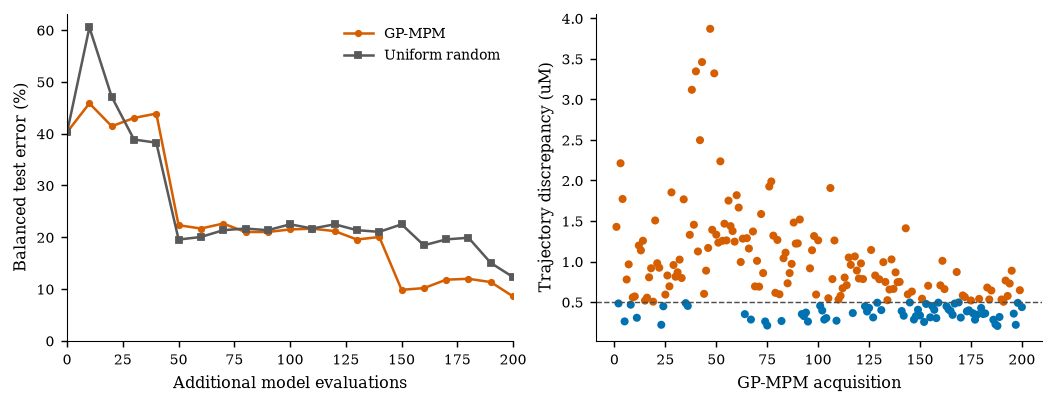

,method,additional_evaluations,test_error,balanced_error,compatible_kept,incompatible_rejected
20,GP-MPM,200,0.07,0.085664,0.886364,0.942308
41,Uniform random,200,0.09,0.122960,0.818182,0.935897


In [51]:
N_TEST_POINTS = 200
TEST_DESIGN_SEED = 2026
COMPARISON_STEPS = np.arange(0, 201, 10)
unit = qmc.Sobol(d=dim_beta, scramble=True, seed=TEST_DESIGN_SEED).random_base2(8)[:N_TEST_POINTS]
X_test = region_lower[0]+unit*(region_upper[0]-region_lower[0])
for training in (X_gp, X_random):
    assert not np.any(np.all(np.isclose(X_test[:, None], training[None], rtol=0, atol=1e-12), axis=2))
test_rows = [compute_point(x, "test") for x in X_test]
rho_test = np.array([r["rho"] for r in test_rows])
b_test = np.array([r["b"] for r in test_rows])
true_test_valid = rho_test <= epsilon
assert true_test_valid.any() and (~true_test_valid).any()
beta_test = np.array([r["beta"] for r in test_rows])
np.savez_compressed(RESULTS_DIR / "gp_hp_test_1020.npz", X_test=X_test,
    **{key: np.array([r[key] for r in test_rows]) for key in
       ("rho", "b", "v", "beta", "trajectories", "distances")},
    test_design_seed=TEST_DESIGN_SEED, epsilon=epsilon, gamma=gamma,
    detailed_model_SHA256=np.array(hashlib.sha256(CLEAN_SBML.read_bytes()).hexdigest()))
comparison_rows = []
for method, X, rho, constants, scales in (
    ("GP-MPM", X_gp, rho_gp, mpm_kernel_constants, mpm_kernel_length_scales),
    ("Uniform random", X_random, rho_random, random_kernel_constants, random_kernel_length_scales)):
    for step in COMPARISON_STEPS:
        fitted_kernel = ConstantKernel(constants[step], "fixed") * RBF(scales[step], "fixed")
        gp = GaussianProcessRegressor(kernel=fitted_kernel, alpha=GP_NOISE, optimizer=None, normalize_y=False)
        gp.fit(X[:T0+step], (epsilon-rho[:T0+step])/validity_scale)
        predicted = gp.predict(X_test) >= 0
        good_kept = float(np.mean(predicted[true_test_valid]))
        bad_rejected = float(np.mean(~predicted[~true_test_valid]))
        comparison_rows.append(dict(method=method, additional_evaluations=int(step),
            test_error=float(np.mean(predicted!=true_test_valid)),
            balanced_error=1-.5*(good_kept+bad_rejected),
            compatible_kept=good_kept, incompatible_rejected=bad_rejected))
learning_comparison = pd.DataFrame(comparison_rows)
fig, axes = plt.subplots(1, 2, figsize=(8, 3), layout="constrained")
for method, color, marker in (("GP-MPM", "#D55E00", "o"), ("Uniform random", ".35", "s")):
    block = learning_comparison[learning_comparison.method==method]
    axes[0].plot(block.additional_evaluations, 100*block.balanced_error,
                 marker=marker, ms=3, color=color, label=method)
axes[0].set(xlabel="Additional model evaluations", ylabel="Balanced test error (%)",
            xlim=(0, N_MPM_STEPS), ylim=(0, None))
axes[0].legend(frameon=False)
axes[1].scatter(np.arange(1,N_MPM_STEPS+1),rho_gp[T0:],s=12,
                c=np.where(rho_gp[T0:]<=epsilon,"#0072B2","#D55E00"))
axes[1].axhline(epsilon,color=".3",ls="--",lw=.8)
axes[1].set(xlabel="GP-MPM acquisition",ylabel="Trajectory discrepancy (uM)")
fig.savefig(OUT / "gp_hp_learning_1020.pdf",bbox_inches="tight")
plt.show()
display(learning_comparison.groupby("method").tail(1))


In [52]:
SCREENING_LEVELS = (0.5, 0.8, 0.9)
mean, std = gp_mpm.predict(X_test, return_std=True)
local_probabilities = ndtr(mean/np.maximum(std, 1e-12))
screening_rows = []
for zeta in SCREENING_LEVELS:
    retained = local_probabilities > zeta
    good_kept = float(np.mean(retained[true_test_valid]))
    bad_rejected = float(np.mean(~retained[~true_test_valid]))
    screening_rows.append(dict(zeta=zeta,
        compatible_kept=int(np.sum(retained & true_test_valid)), compatible_total=int(true_test_valid.sum()),
        compatible_kept_pct=100*good_kept,
        incompatible_rejected=int(np.sum(~retained & ~true_test_valid)),
        incompatible_total=int((~true_test_valid).sum()), incompatible_rejected_pct=100*bad_rejected,
        balanced_error=1-.5*(good_kept+bad_rejected)))
screening_summary = pd.DataFrame(screening_rows)
display(screening_summary)

GP_SCREENING_LEVEL = 0.8
region_rows = []
for region in range(N_REGIONS):
    mask = np.full(N_TEST_POINTS, region == 0)
    good = mask & true_test_valid
    bad = mask & ~true_test_valid
    retained = local_probabilities > GP_SCREENING_LEVEL
    region_rows.append(dict(region=region+1,
        compatible_kept=int(np.sum(retained & good)), compatible_total=int(good.sum()),
        incompatible_rejected=int(np.sum(~retained & bad)), incompatible_total=int(bad.sum())))
display(pd.DataFrame(region_rows))

# Predictions only: how much of the broad prior the learned screen admits.
N_PRIOR_PREDICTIONS = 16384
X_prior_prediction = qmc.Sobol(d=dim_beta, scramble=False).random(N_PRIOR_PREDICTIONS)
mean, std = gp_mpm.predict(X_prior_prediction, return_std=True)
prior_probabilities = ndtr(mean/np.maximum(std, 1e-12))
prior_screen_summary = pd.DataFrame([
    dict(zeta=zeta, prior_draws=N_PRIOR_PREDICTIONS,
         admitted=int(np.sum(prior_probabilities>zeta)),
         rejected_pct=100*float(np.mean(prior_probabilities<=zeta))) for zeta in SCREENING_LEVELS])
print("Predicted screening over the broad prior:")
display(prior_screen_summary)


,zeta,compatible_kept,compatible_total,compatible_kept_pct,incompatible_rejected,incompatible_total,incompatible_rejected_pct,balanced_error
0,0.5,39,44,88.636364,147,156,94.230769,0.085664
1,0.8,24,44,54.545455,156,156,100.000000,0.227273
2,0.9,17,44,38.636364,156,156,100.000000,0.306818


,region,compatible_kept,compatible_total,incompatible_rejected,incompatible_total
0,1,24,44,156,156


Predicted screening over the broad prior:


,zeta,prior_draws,admitted,rejected_pct
0,0.5,16384,51,99.688721
1,0.8,16384,0,100.000000
2,0.9,16384,0,100.000000


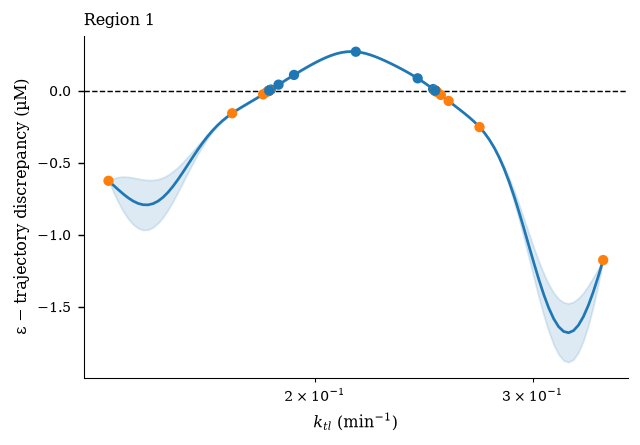

In [53]:
SLICE_PARAMETER = "ktl"
N_SLICE_POINTS = 101
j = params_to_estimate_detailed.index(SLICE_PARAMETER)
fig, axes = plt.subplots(1, N_REGIONS, figsize=(5, 3.5), sharey=True, squeeze=False)
for region, ax in enumerate(axes.ravel()):
    X_slice = np.repeat(region_centres[region][None], N_SLICE_POINTS, axis=0)
    X_slice[:, j] = np.linspace(region_lower[region, j], region_upper[region, j], N_SLICE_POINTS)
    mean, std = gp_mpm.predict(X_slice, return_std=True)
    rates = np.exp(log_lower_bounds[j]+X_slice[:, j]*(log_upper_bounds[j]-log_lower_bounds[j]))
    mean, std = mean*validity_scale, std*validity_scale
    ax.plot(rates, mean, color="tab:blue", lw=1.5)
    ax.fill_between(rates, mean-2*std, mean+2*std, color="tab:blue", alpha=.15)
    fixed = np.delete(np.arange(dim_beta), j)
    matches = np.max(np.abs(X_initial[:, fixed]-region_centres[region, fixed]), axis=1) < 1e-10
    observed_rates = np.exp(log_lower_bounds[j]+X_initial[matches, j]*(log_upper_bounds[j]-log_lower_bounds[j]))
    observed_v = epsilon-rho_initial[matches]
    ax.scatter(observed_rates, observed_v, s=22,
               c=np.where(observed_v>=0, "tab:blue", "tab:orange"), zorder=3)
    ax.axhline(0, color="k", ls="--", lw=.8)
    ax.set(xscale="log", title=f"Region {region+1}", xlabel=r"$k_{tl}$ (min$^{-1}$)")
for ax in axes[:, 0]:
    ax.set_ylabel("ε − trajectory discrepancy (µM)")
fig.tight_layout()
plt.show()


## Save GP_hp and its construction record

Save the production and random-comparison checkpoints with short names.
Record the nine-state model, high-level inputs, priors, seed search,
focused design, independent test set, kernel histories and measured stages.
GP construction includes the fresh search, local probes and GP-MPM fit.


In [54]:
RUN_TAG = "1020"
GP_MPM_FILE = RESULTS_DIR / f"gp_hp_{RUN_TAG}.npz"
GP_RANDOM_FILE = RESULTS_DIR / f"gp_hp_rand_{RUN_TAG}.npz"
learning_settings = dict(
    initial_design="one minimum-discrepancy compatible centre; two-sided coordinate probes and boundary bisection",
    seed_source=str(SEED_SOURCE_FILE), seed_source_SHA256=hashlib.sha256(SEED_SOURCE_FILE.read_bytes()).hexdigest(),
    selected_seed_indices=selected_seed_indices, selected_search_points=N_SEED_TRAINING_POINTS,
    regions=N_REGIONS, region_half_width_normalized_log=REGION_HALF_WIDTH,
    region_centres=region_centres.tolist(), region_lower=region_lower.tolist(), region_upper=region_upper.tolist(),
    initial_new_model_evaluations=INITIAL_NEW_EVALUATIONS, cached_initial_points=cached_initial_points,
    initial_training_points=T0, initial_evaluations=T0, additional_evaluations=N_MPM_STEPS,
    new_production_model_evaluations=PRODUCTION_EVALUATION_BUDGET+len(seed_rows),
    focused_model_evaluations=PRODUCTION_EVALUATION_BUDGET, fresh_seed_evaluations=len(seed_rows),
    integration_design="unscrambled Sobol; equal mixture over selected neighborhoods",
    integration_points=N_INTEGRATION_POINTS,
    candidate_design="unscrambled Sobol; same neighborhood mixture",
    acquisition_candidates=N_ACQUISITION_CANDIDATES, acquisition_batch_size=ACQUISITION_BATCH_SIZE,
    kernel="Constant * ARD RBF", initial_length_scale=GP_INITIAL_LENGTH_SCALE,
    length_scale_bounds=GP_LENGTH_SCALE_BOUNDS, constant_bounds=GP_CONSTANT_BOUNDS,
    kernel_optimization_interval=GP_OPTIMIZATION_INTERVAL, optimizer_restarts=GP_OPTIMIZER_RESTARTS,
    warm_start_kernel=True, gp_noise=GP_NOISE, normalize_y=False, mpm_local_radius=MPM_ALPHA,
    target="epsilon minus ceil(gamma*M)-th discrepancy; divided by initial target SD",
    epsilon_uM=epsilon, gamma=gamma, screening_level=GP_SCREENING_LEVEL,
    optimizer_seed=GP_OPTIMIZER_SEED, random_control_seed=RANDOM_CONTROL_SEED,
    local_test_points=N_TEST_POINTS, test_design="independent scrambled Sobol", test_design_seed=TEST_DESIGN_SEED,
    seed_sobol_points=2**SEED_SOBOL_POWER, seed_local_evaluation_limit=SEED_LOCAL_EVALUATIONS,
    seed_refinement="bounded Powell from smallest-discrepancy Sobol tuple",
    evaluation_scope="selected neighborhoods", reduced_trajectories=len(reduced_posterior_trajectories),
    GP_input_file=str(GP_INPUT_FILE),
    GP_input_SHA256=hashlib.sha256(GP_INPUT_FILE.read_bytes()).hexdigest(),
    reduced_result_file=gp_inputs["reduced_result_file"].item(),
    reduced_result_SHA256=gp_inputs["reduced_result_SHA256"].item())
common_gp_metadata = dict(
    concentration_unit=np.array("uM"), DNA_NM_TO_UM=np.array(1e-3),
    dna_concs=dna_concs, timepoints=timepoints, epsilon=epsilon, gamma=gamma,
    validity_scale=validity_scale, detailed_param_names=np.array(params_to_estimate_detailed),
    gp_training_seconds_scope=np.array("fresh deterministic seed search, 100 new local probes, initial fit, 200 GP-MPM acquisitions"),
    mapping=np.array("GP_hp"), model_level=np.array("phenomenological"),
    fresh_seed_evaluations=len(seed_rows), cached_seed_evaluations=0,
    GP_input_file=np.array(str(GP_INPUT_FILE)),
    GP_input_SHA256=np.array(hashlib.sha256(GP_INPUT_FILE.read_bytes()).hexdigest()),
    reduced_result_file=gp_inputs["reduced_result_file"],
    reduced_result_SHA256=gp_inputs["reduced_result_SHA256"],
    reduced_inference_seconds=gp_inputs["reduced_inference_seconds"],
    reduced_gp_preparation_seconds=gp_inputs["reduced_gp_preparation_seconds"],
    lower_bounds_detailed=lower_bounds_detailed, upper_bounds_detailed=upper_bounds_detailed,
    gp_noise=GP_NOISE, T0=T0, N_MPM_STEPS=N_MPM_STEPS,
    X_test=X_test, b_test=b_test, true_test_valid=true_test_valid,
    settings_json=np.array(json.dumps(learning_settings)),
    fixed_detailed_parameters_json=np.array(json.dumps(fixed_detailed_parameters)),
    fixed_reduced_parameters_json=np.array(json.dumps(fixed_reduced_parameters)), run_tag=np.array(RUN_TAG),
    detailed_model_file=np.array(str(CLEAN_SBML)),
    detailed_model_SHA256=np.array(hashlib.sha256(CLEAN_SBML.read_bytes()).hexdigest()),
    n_states=len(M.get_species_dictionary()),
    region_centres=region_centres, region_lower=region_lower, region_upper=region_upper)
for checkpoint, method, gp, X, rho, b in (
    (GP_MPM_FILE, "GP-MPM", gp_mpm, X_gp, rho_gp, b_gp),
    (GP_RANDOM_FILE, "Uniform random", gp_random, X_random, rho_random, b_random)):
    timing = {"gp_training_seconds": gp_training_seconds} if method == "GP-MPM" else {}
    np.savez_compressed(checkpoint, **common_gp_metadata, **timing, method=np.array(method),
        test_points_held_out_from_this_gp=np.array(True),
        X_gp=X, rho_gp=rho, b_gp=b, v_gp=epsilon-rho,
        beta_gp=np.exp(log_lower_bounds+X*(log_upper_bounds-log_lower_bounds)),
        gp_kernel_constant=float(gp.kernel_.k1.constant_value),
        gp_kernel_length_scale=gp.kernel_.k2.length_scale)
    print("Saved:", checkpoint)
np.savez_compressed(RESULTS_DIR / "gp_hp_history_1020.npz",
    X_initial=X_initial, rho_initial=rho_initial, b_initial=b_initial,
    X_gp=X_gp, rho_gp=rho_gp, X_random=X_random, rho_random=rho_random,
    X_integration=X_integration, X_test=X_test, rho_test=rho_test, b_test=b_test,
    mpm_kernel_constants=mpm_kernel_constants, mpm_kernel_length_scales=mpm_kernel_length_scales,
    random_kernel_constants=random_kernel_constants, random_kernel_length_scales=random_kernel_length_scales,
    mpm_optimization_steps=mpm_optimization_steps, random_optimization_steps=random_optimization_steps,
    mpm_selected_regions=mpm_selected_regions, random_query_regions=random_query_regions,
    mpm_best_acquisition=mpm_best_acquisition, mpm_selected_integration_counts=mpm_selected_integration_counts,
    settings_json=np.array(json.dumps(learning_settings)))
screening_summary.to_csv(OUT / "gp_hp_screening_1020.csv", index=False)
learning_comparison.to_csv(OUT / "gp_hp_learning_1020.csv", index=False)
gp_timing = dict(fresh_seed_search_seconds=seed_preparation_seconds,
    initial_local_evaluations_seconds=initial_evaluation_seconds,
    GP_fit_and_MPM_seconds=initial_gp_fit_seconds+mpm_seconds,
    GP_construction_seconds=gp_training_seconds,
    timing_scope=str(common_gp_metadata["gp_training_seconds_scope"]),
    initial_new_model_evaluations=INITIAL_NEW_EVALUATIONS, cached_initial_points=cached_initial_points,
    GP_MPM_iterations=N_MPM_STEPS, new_production_model_evaluations=PRODUCTION_EVALUATION_BUDGET+len(seed_rows),
    focused_model_evaluations=PRODUCTION_EVALUATION_BUDGET, fresh_seed_evaluations=len(seed_rows),
    epsilon=epsilon, gamma=gamma, regions=N_REGIONS,
    local_test_points=N_TEST_POINTS, platform=platform.platform(), processor=platform.processor())
(RESULTS_DIR / "gp_hp_timing_1020.json").write_text(json.dumps(gp_timing, indent=2)+chr(10))
print(json.dumps(gp_timing, indent=2))
gp_inputs.close()


Saved: c:\Users\ayush\Box\Research\hierarchical-validation-id\hierarch-inf\examples\results\gp_hp_1020.npz
Saved: c:\Users\ayush\Box\Research\hierarchical-validation-id\hierarch-inf\examples\results\gp_hp_rand_1020.npz
{
  "fresh_seed_search_seconds": 21.892156000016257,
  "initial_local_evaluations_seconds": 1.089792300015688,
  "GP_fit_and_MPM_seconds": 147.60781259997748,
  "GP_construction_seconds": 170.58976090000942,
  "timing_scope": "fresh deterministic seed search, 100 new local probes, initial fit, 200 GP-MPM acquisitions",
  "initial_new_model_evaluations": 100,
  "cached_initial_points": 29,
  "GP_MPM_iterations": 200,
  "new_production_model_evaluations": 2347,
  "focused_model_evaluations": 300,
  "fresh_seed_evaluations": 2047,
  "epsilon": 0.5,
  "gamma": 0.5,
  "regions": 1,
  "local_test_points": 200,
  "platform": "Windows-11-10.0.26200-SP0",
  "processor": "Intel64 Family 6 Model 204 Stepping 2, GenuineIntel"
}


## Trained checkpoint

Use `results/gp_hp_1020.npz` to screen nine-state phenomenological inference.
The high-level to 38-state GP is `results/gp_mpm_exp3_result_eps0p5_1020.npz`.
Review the independent-test learning and screening tables above before
launching the guided run.


## Baseline inference -- RUN ON HPC

Run the existing nominal-rate baseline with 256 walkers and 40,000 steps.


In [ ]:
from hierarch_inf.gene_expression import phenomenological as baseline

baseline.DATA_FILE = DATA_FILE
baseline.main()


## GP-guided inference -- RUN ON HPC

Run the existing fixed-GP proposal filter at zeta = 0.8, then rerun the figure section to inspect the new results.


In [ ]:
from hierarch_inf.gene_expression import phenomenological_guided as guided_inference

guided_inference.DATA_FILE = DATA_FILE
guided_inference.main()
